In [1]:
import pickle
import warnings
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import bootstrap as scipy_bootstrap

# ----------------------------------------------------------------------
# Roots & output
# ----------------------------------------------------------------------
HJN_ROOT  = Path("/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN")
BASE_ROOT = Path("/home/thomasdev/Desktop/noethers_projects/noethers-razor")

FIG_DIR = HJN_ROOT / "manuscript_figures"        # all paper figures land here
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------
# Statistics config (frozen to match plot_summary_statistics)
# ----------------------------------------------------------------------
CONF_LEVEL = 0.95
N_BOOT     = 10_000
BOOT_RNG_SEED = 0 

# ----------------------------------------------------------------------
# Colorblind-safe palette (Okabe-Ito)
# ----------------------------------------------------------------------
PALETTE = {
    'HJN':      '#D55E00',   # vermillion  (ours)
    'Baseline': '#0072B2',   # blue        (Noether's Razor)
    'Truth':    '#000000',   # black       (ground truth; unused in Exp 1)
}
METHOD_LABEL = {'HJN': 'HJN (ours)', 'Baseline': "Noether's Razor"}
METHOD_ORDER = ['Baseline', 'HJN']   # draw baseline first so HJN sits on top

# ----------------------------------------------------------------------
# Figure style — adjust ONE block per venue, everything inherits
# ----------------------------------------------------------------------
FIG_CONFIG = {
    'text_width_in': 6.9,    # full text width: NeurIPS/ICML 2-col ~6.9", single-col ~3.3"
    'panel_aspect':  0.80,   # panel height / width
    'font_size':     9,
    'tick_size':     8,
    'legend_size':   8,
    'use_tex':       False,  # True ONLY if a LaTeX install is present (exact font match)
    'font_family':   'serif',
}

def apply_style(cfg=FIG_CONFIG):
    mpl.rcParams.update({
        'pdf.fonttype': 42, 'ps.fonttype': 42,        # embed real fonts (publisher-safe)
        'savefig.dpi': 300, 'figure.dpi': 120,
        'savefig.bbox': 'tight',
        'font.size': cfg['font_size'],
        'axes.titlesize': cfg['font_size'],
        'axes.labelsize': cfg['font_size'],
        'xtick.labelsize': cfg['tick_size'],
        'ytick.labelsize': cfg['tick_size'],
        'legend.fontsize': cfg['legend_size'],
        'axes.grid': True, 'grid.alpha': 0.3,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.2,
        'font.family': cfg['font_family'],
        'text.usetex': cfg['use_tex'],
        'mathtext.fontset': 'cm',
    })

apply_style()


# ----------------------------------------------------------------------
# Task metadata shared by all three experiments
# ----------------------------------------------------------------------
TASK_LABEL = {
    1: 'Task 1\nIdeal mass–spring',
    2: 'Task 2\nIdeal pendulum',
    3: 'Task 3\nReal pendulum',
    4: 'Task 4\nHénon–Heiles',
}

# Which canonical pair (q_i, p_i) the Exp-2 phase panel shows, per task.
# n=1 tasks have one pair. Task 4 uses (y, p_y): the DOF carrying the
# asymmetric cubic term -y^3/3, where anharmonicity is most visible.
PHASE_PAIR   = {1: 0, 2: 0, 3: 0, 4: 1}
PHASE_LABELS = {1: ('$q$', '$p$'), 2: ('$q$', '$p$'),
                3: ('$q$', '$p$'), 4: ('$y$', '$p_y$')}

def _dof(a, i=0):
    """(T,) -> (T,) unchanged; (T,n) -> column i. Lets n=1 pickles flow through."""
    a = np.asarray(a)
    return a if a.ndim == 1 else a[:, i]

def _dof2d(a):
    """(T,) -> (T,1); (T,n) -> unchanged."""
    a = np.asarray(a)
    return a[:, None] if a.ndim == 1 else a

In [4]:
DATASETS = ['multiple_periods', 'high_energy']   # main body / appendix
TASKS    = [1, 2, 4]
ACC_SUB  = "prediction_results_all_trajectories"
TIM_SUB  = "benchmark_outputs"

# Accuracy filenames are identical across roots: task_{T}_results_{dataset}.pkl
def _acc_paths():
    out = {}
    for ds in DATASETS:
        out[ds] = {}
        for t in TASKS:
            name = f"task_{t}_results_{ds}.pkl"
            out[ds][t] = {
                'HJN':      HJN_ROOT  / ACC_SUB / name,
                'Baseline': BASE_ROOT / ACC_SUB / name,
            }
    return out

# Timing filenames are NOT uniform — listed literally. Verify the HJN high_energy
# entries (no `_final`) vs the rest (with `_final`).
TIMING_NAMES = {
    ('HJN', 1, 'multiple_periods'): "hjn_task1_multiple_periods_final.pkl",
    ('HJN', 1, 'high_energy'):      "hjn_task1_high_energy.pkl",
    ('HJN', 2, 'multiple_periods'): "hjn_task2_multiple_periods_final.pkl",
    ('HJN', 2, 'high_energy'):      "hjn_task2_high_energy.pkl",
    ('Baseline', 1, 'multiple_periods'): "noethers_task1_multiple_periods_final.pkl",
    ('Baseline', 1, 'high_energy'):      "noethers_task1_high_energy_final.pkl",
    ('Baseline', 2, 'multiple_periods'): "noethers_task2_multiple_periods_final.pkl",
    ('Baseline', 2, 'high_energy'):      "noethers_task2_high_energy_final.pkl",
}

TIMING_NAMES.update({
    ('HJN',      4, 'multiple_periods'): "hjn_task4_multiple_periods_final.pkl",
    ('HJN',      4, 'high_energy'):      "hjn_task4_high_energy.pkl",
    ('Baseline', 4, 'multiple_periods'): "noethers_task4_multiple_periods_final.pkl",
    ('Baseline', 4, 'high_energy'):      "noethers_task4_high_energy_final.pkl",
})

def _tim_paths():
    root = {'HJN': HJN_ROOT, 'Baseline': BASE_ROOT}
    out = {}
    for ds in DATASETS:
        out[ds] = {}
        for t in TASKS:
            out[ds][t] = {
                m: root[m] / TIM_SUB / TIMING_NAMES[(m, t, ds)]
                for m in ('HJN', 'Baseline')
            }
    return out

ACC_PATHS = _acc_paths()
TIM_PATHS = _tim_paths()

EXP1_SEEDS = (42, 52, 62)

def _acc_path_seed(seed, t, ds):
    """HJN all-trajectory results of one training seed (seed 42 = ACC_PATHS)."""
    if seed == 42:
        return ACC_PATHS[ds][t]['HJN']
    return (HJN_ROOT / "seed_results" / f"{ACC_SUB}_seed_{seed}"
            / f"task_{t}_results_{ds}.pkl")

In [5]:
def _load(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    with open(path, "rb") as f:
        return pickle.load(f)

ACC = {ds: {t: {m: _load(p) for m, p in d.items()} for t, d in td.items()}
       for ds, td in ACC_PATHS.items()}
TIM = {ds: {t: {m: _load(p) for m, p in d.items()} for t, d in td.items()}
       for ds, td in TIM_PATHS.items()}

ACC_SEEDS = {ds: {t: {s: (ACC[ds][t]['HJN'] if s == 42 else _load(_acc_path_seed(s, t, ds)))
                      for s in EXP1_SEEDS} for t in TASKS} for ds in DATASETS}

print("Loaded OK. Shapes / hardware:")
for ds in DATASETS:
    for t in TASKS:
        for m in METHOD_ORDER:
            a = ACC[ds][t][m]
            dev = TIM[ds][t][m]['timing_stats'].get('device_name', '?')
            print(f"  [{ds:16s} | task{t} | {m:8s}] "
                  f"N_traj={a['N_traj']:3d} N_obs={a['N_obs']:3d}  gpu={dev}")

Loaded OK. Shapes / hardware:
  [multiple_periods | task1 | Baseline] N_traj= 24 N_obs= 97  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task1 | HJN     ] N_traj= 24 N_obs= 97  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task2 | Baseline] N_traj= 20 N_obs=144  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task2 | HJN     ] N_traj= 20 N_obs=144  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task4 | Baseline] N_traj= 16 N_obs=334  gpu=NVIDIA GeForce RTX 3060
  [multiple_periods | task4 | HJN     ] N_traj= 16 N_obs=334  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task1 | Baseline] N_traj= 25 N_obs= 32  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task1 | HJN     ] N_traj= 25 N_obs= 32  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task2 | Baseline] N_traj= 13 N_obs= 37  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task2 | HJN     ] N_traj= 13 N_obs= 37  gpu=NVIDIA GeForce RTX 3060
  [high_energy      | task4 | Baseline] N_traj= 16 N_obs=115  gpu=NVID

In [6]:
def normalized_loss_matrix(results):
    """
    L / sqrt(E), computed from the RAW loss matrix.

    Most pickles store the raw (un-normalized) matrix under 'loss_matrix'.
    The Hénon–Heiles baseline instead stores an already-normalized copy there
    (with divergent entries median-imputed) and keeps the raw one under
    'loss_matrix_raw'. Prefer the raw key whenever present so that sqrt(E) is
    applied exactly once. Without this, Task 4 baseline errors are inflated by
    1/sqrt(E) ~ 3x.
    """
    key = 'loss_matrix_raw' if 'loss_matrix_raw' in results else 'loss_matrix'
    L = np.asarray(results[key], dtype=float)
    E = np.asarray(results['energies'], dtype=float)
    if np.any(E <= 1e-12):
        raise ValueError("sqrt(E) normalization requires positive energies.")
    n_bad = int(np.sum(~np.isfinite(L)))
    if n_bad:
        raise ValueError(
            f"loss matrix ('{key}') has {n_bad} non-finite entries. Divergent "
            f"rollouts must be reported explicitly, not silently aggregated.")
    return L / np.sqrt(E)[np.newaxis, :]          # (N_obs, N_traj)

def _bca_mean_ci(values, conf=CONF_LEVEL, n_boot=N_BOOT, rng_seed=BOOT_RNG_SEED):
    kw = dict(n_resamples=n_boot, confidence_level=conf, method='BCa')
    try:
        try:
            r = scipy_bootstrap((values,), np.mean, rng=np.random.default_rng(rng_seed), **kw)
        except TypeError:   # SciPy < 1.15 has no `rng`; older name is `random_state`
            r = scipy_bootstrap((values,), np.mean,
                                random_state=np.random.default_rng(rng_seed), **kw)
        return float(r.confidence_interval.low), float(r.confidence_interval.high)
    except Exception as e:
        warnings.warn(f"BCa CI failed ({e}); returning NaNs.")
        return float('nan'), float('nan')

def accuracy_stats(results):
    """Per-trajectory median over obs -> cross-trajectory descriptives + BCa CI."""
    L = normalized_loss_matrix(results)
    per_traj_med = np.median(L, axis=0)                       # (N_traj,)
    lo, hi = _bca_mean_ci(per_traj_med)
    return {
        'L': L,
        'energies': np.asarray(results['energies']),
        't': np.asarray(results.get('t', np.arange(results['N_obs']))),
        'per_traj_median': per_traj_med,
        'mean':   float(np.mean(per_traj_med)),
        'std':    float(np.std(per_traj_med, ddof=1)),
        'median': float(np.median(per_traj_med)),
        'q1':     float(np.percentile(per_traj_med, 25)),
        'q3':     float(np.percentile(per_traj_med, 75)),
        'ci_lo': lo, 'ci_hi': hi,
        'N_traj': results['N_traj'], 'N_obs': results['N_obs'],
    }

def timing_stats(full):
    """Runtime (ms) + memory (MB). Central=mean over obs, range=[min,max] over obs."""
    ts = full['timing_stats']; ms = full['memory_stats']
    return {
        'per_obs_mean_ms': np.asarray(ts['per_obs_mean']) * 1e3,
        'per_obs_std_ms':  np.asarray(ts['per_obs_std'])  * 1e3,
        'mean_ms': ts['mean_s'] * 1e3,
        'min_ms':  ts['min_s']  * 1e3,
        'max_ms':  ts['max_s']  * 1e3,
        'meas_noise_ms': ts['measurement_noise_mean_ms'],
        'mem_mean': ms['peak_MB_above_baseline_mean'],
        'mem_min':  ms['peak_MB_above_baseline_min'],
        'mem_max':  ms['peak_MB_above_baseline_max'],
        'device':   ts.get('device_name', '?'),
        'n_repeats': ts.get('n_repeats', '?'),
    }

# Per-seed HJN statistics; worst seed = largest mean L2/sqrtE, per task and test set.
EXP1_STATS = {ds: {t: {s: accuracy_stats(ACC_SEEDS[ds][t][s]) for s in EXP1_SEEDS}
                   for t in TASKS} for ds in DATASETS}
EXP1_WORST = {ds: {t: max(EXP1_SEEDS, key=lambda s: EXP1_STATS[ds][t][s]['mean'])
                   for t in TASKS} for ds in DATASETS}

In [7]:
def plot_experiment1_grid(dataset, acc=ACC, tim=TIM, *,
                          log_loss=False, log_time=False,
                          energy_jitter=0.0, band_alpha=0.22,
                          dense_marker_cutoff=150,
                          include_timing=False, other_seed_lw=0.6,
                          save=True, fname=None):
    """
    len(TASKS) rows x 3 cols (L2/sqrtE vs energy | error vs obs time |
    inference time vs obs time). Both methods overlaid.
    log_loss -> log y on cols 1-2 ; log_time -> log y on col 3. Defaults linear.
    Rows with more than `dense_marker_cutoff` observations drop line markers.
    """
    cfg = FIG_CONFIG
    ncol = 3 if include_timing else 2
    pw  = cfg['text_width_in'] / ncol
    ph  = (cfg['text_width_in'] / 3.0) * cfg['panel_aspect']   # same row height as the 3-column layout
    fig, axes = plt.subplots(len(TASKS), ncol, figsize=(ncol * pw, len(TASKS) * ph),
                             squeeze=False)

    COL_HEADERS = ['Error vs. energy',
                   'Error vs. observation time',
                   'Inference time'][:ncol]

    for r, t in enumerate(TASKS):
        ax_e, ax_t = axes[r][0], axes[r][1]
        ax_time = axes[r][2] if include_timing else None
        w = EXP1_WORST[dataset][t]

        # HJN seeds other than the worst: thin mean line (col 1), thin median curve (col 2)
        for s_ in EXP1_SEEDS:
            if s_ == w:
                continue
            so = EXP1_STATS[dataset][t][s_]
            ax_e.axhline(so['mean'], color=PALETTE['HJN'], lw=other_seed_lw, zorder=2)
            ax_t.plot(so['t'], np.median(so['L'], axis=1), '-',
                      lw=other_seed_lw, color=PALETTE['HJN'])

        for m in METHOD_ORDER:
            c = PALETTE[m]
            s  = EXP1_STATS[dataset][t][w] if m == 'HJN' else accuracy_stats(acc[dataset][t][m])
            L, E, tt = s['L'], s['energies'], s['t']
            ms_row = 2.6 if len(tt) <= dense_marker_cutoff else 0.0

            # ---- Panel 1: L2/sqrtE vs energy (per-traj median + IQR across obs) ----
            med = s['per_traj_median']
            q25 = np.percentile(L, 25, axis=0)
            q75 = np.percentile(L, 75, axis=0)
            x   = E * (1 + (energy_jitter if m == 'HJN' else -energy_jitter))
            ax_e.errorbar(x, med, yerr=[med - q25, q75 - med],
                          fmt='o', ms=3.5, color=c, ecolor=c, elinewidth=0.9,
                          capsize=2, capthick=0.9, alpha=0.85, zorder=3)
            ax_e.axhline(s['mean'], color=c, lw=1.1, zorder=2)
            ax_e.axhspan(s['ci_lo'], s['ci_hi'], color=c, alpha=band_alpha,
                         lw=0, zorder=1)

            # ---- Panel 2: error vs obs time (median + IQR across trajectories) ----
            po_med = np.median(L, axis=1)
            po_q25 = np.percentile(L, 25, axis=1)
            po_q75 = np.percentile(L, 75, axis=1)
            ax_t.fill_between(tt, po_q25, po_q75, color=c, alpha=band_alpha, lw=0)
            ax_t.plot(tt, po_med, '-o', ms=ms_row, lw=1.0, color=c)
            ax_t.axhline(s['mean'], color=c, lw=1.0, ls='--', alpha=0.8)

            # ---- Panel 3: inference time per obs (optional; seed-42 timing runs) ----
            if include_timing:
                T = timing_stats(tim[dataset][t][m])
                mean_ms, std_ms = T['per_obs_mean_ms'], T['per_obs_std_ms']
                xt = tt if len(tt) == len(mean_ms) else np.arange(len(mean_ms))
                ax_time.fill_between(xt, mean_ms - std_ms, mean_ms + std_ms,
                                     color=c, alpha=band_alpha, lw=0)
                ax_time.plot(xt, mean_ms, '-o', ms=ms_row, lw=1.0, color=c)

        # axis scales
        if log_loss:
            ax_e.set_yscale('log'); ax_t.set_yscale('log')
            ax_e.set_ylabel(r'$L_2/\sqrt{E}$ (log)')
            ax_t.set_ylabel(r'$L_2/\sqrt{E}$ (log)')
        else:
            ax_e.set_ylabel(r'$L_2/\sqrt{E}$')
            ax_t.set_ylabel(r'$L_2/\sqrt{E}$')

        if include_timing:
            if log_time:
                ax_time.set_yscale('log')
                ax_time.set_ylabel('Inference time (ms, log)')
            else:
                ax_time.set_ylabel('Inference time (ms)')

        # x labels only on the bottom row
        if r == len(TASKS) - 1:
            ax_e.set_xlabel(r'Trajectory energy $E$')
            ax_t.set_xlabel(r'Observation time $t$')
            if include_timing:
                ax_time.set_xlabel(r'Observation time $t$')

        # rotated row label on the far left
        ax_e.annotate(TASK_LABEL[t], xy=(0, 0.5),
                      xytext=(-ax_e.yaxis.labelpad - 16, 0),
                      xycoords=ax_e.yaxis.label, textcoords='offset points',
                      ha='right', va='center', rotation=90,
                      fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=8)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], marker='o', ms=4, lw=1.4,
                      label=f"{METHOD_LABEL['HJN']}, worst seed"),
               Line2D([0], [0], color=PALETTE['HJN'], lw=other_seed_lw,
                      label=f"{METHOD_LABEL['HJN']}, other seeds"),
               Line2D([0], [0], color=PALETTE['Baseline'], marker='o', ms=4, lw=1.4,
                      label=METHOD_LABEL['Baseline'])]
    fig.legend(handles=handles, loc='lower center', ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.03, 0.04, 1, 1))

    print(f"Exp 1 figure ({dataset}): HJN worst seed per task (largest mean L2/sqrtE): "
          + ", ".join(f"task{t}={EXP1_WORST[dataset][t]}" for t in TASKS))
    if save:
        if fname is None:
            tag = 'main' if dataset == 'multiple_periods' else 'appendix'
            sfx = ('_logloss' if log_loss else '') + ('_timing' if include_timing else '')
            fname = FIG_DIR / f"exp1_{tag}_{dataset}{sfx}.pdf"
        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

Exp 1 figure (multiple_periods): HJN worst seed per task (largest mean L2/sqrtE): task1=52, task2=52, task4=62


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp1_main_multiple_periods.pdf


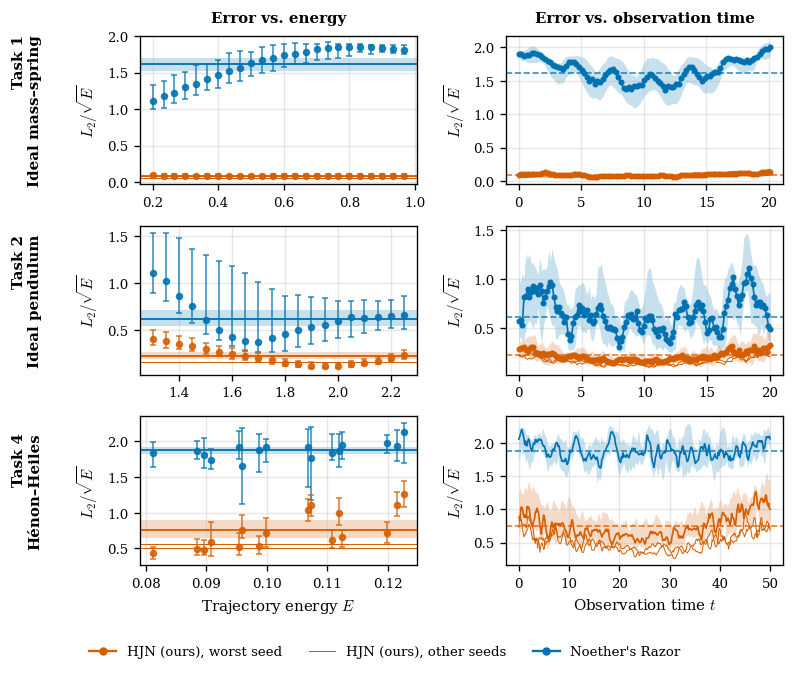

Exp 1 figure (high_energy): HJN worst seed per task (largest mean L2/sqrtE): task1=52, task2=52, task4=62


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp1_appendix_high_energy.pdf


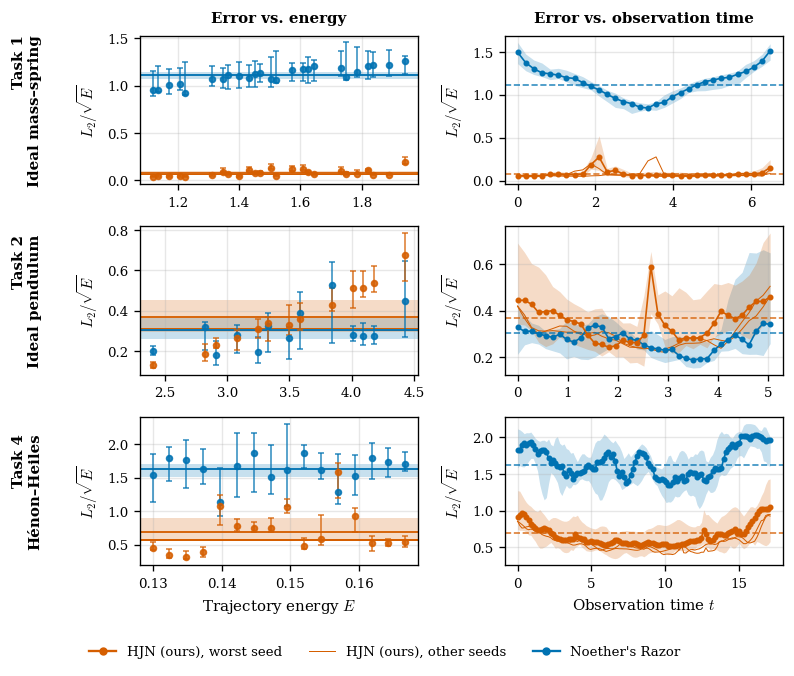

In [8]:
# Main body: temporal extrapolation
fig_main, _ = plot_experiment1_grid('multiple_periods', log_loss=False, log_time=False)
plt.show()

# Appendix: energy extrapolation
fig_app, _ = plot_experiment1_grid('high_energy', log_loss=False, log_time=False)
plt.show()

# If HJN's curve gets squashed near the floor, re-run with log_loss=True:
# plot_experiment1_grid('multiple_periods', log_loss=True)

In [9]:
def print_exp1_numbers(acc=ACC, tim=TIM):
    # row label -> (task, dataset).  A = temporal (multiple_periods), B = energy (high_energy)
    rows = [('T1-A', 1, 'multiple_periods'), ('T1-B', 1, 'high_energy'),
            ('T2-A', 2, 'multiple_periods'), ('T2-B', 2, 'high_energy'),
            ('T4-A', 4, 'multiple_periods'), ('T4-B', 4, 'high_energy')]

    # fairness check: same GPU across methods?
    devs = {TIM[ds][t][m]['timing_stats'].get('device_name')
            for _, t, ds in rows for m in ('HJN', 'Baseline')}
    print("=" * 78)
    print("EXPERIMENT 1 — NUMBERS FOR TABLE 1 (L2/sqrtE, runtime ms, peak GPU mem MB)")
    print("=" * 78)
    print(f"GPU(s) seen across all runs: {devs}")
    if len(devs) > 1:
        print("  !! WARNING: timing runs span different GPUs — not directly comparable.")
    print("CAVEAT: HJN timed in EAGER PyTorch; baseline uses JAX @jit. torch.compile")
    print("        failed (higher-order autograd in forward). Runtime favors baseline.\n")

    latex_rows = []
    for label, t, ds in rows:
        aH, aB = accuracy_stats(acc[ds][t]['HJN']), accuracy_stats(acc[ds][t]['Baseline'])
        tH, tB = timing_stats(tim[ds][t]['HJN']),  timing_stats(tim[ds][t]['Baseline'])

        print(f"----- {label}  (task {t}, {ds}) | N_traj={aH['N_traj']} N_obs={aH['N_obs']} -----")
        for tag, a in (('HJN', aH), ('Base', aB)):
            print(f"  L2/sqrtE {tag:4s}: mean={a['mean']:.4f}  CI=[{a['ci_lo']:.4f}, {a['ci_hi']:.4f}]  "
                  f"median={a['median']:.4f}  IQR=[{a['q1']:.4f}, {a['q3']:.4f}]  std={a['std']:.4f}")
        for tag, T in (('HJN', tH), ('Base', tB)):
            print(f"  runtime  {tag:4s}: {T['mean_ms']:.3f} ms  range=[{T['min_ms']:.3f}, {T['max_ms']:.3f}]  "
                  f"meas_noise={T['meas_noise_ms']:.3f} ms  (n_repeats={T['n_repeats']})")
        for tag, T in (('HJN', tH), ('Base', tB)):
            print(f"  mem(MB)  {tag:4s}: {T['mem_mean']:.1f}  range=[{T['mem_min']:.1f}, {T['mem_max']:.1f}]")
        print()

        latex_rows.append(
            f"{label}\n"
            f"& {aH['mean']:.3f} [{aH['ci_lo']:.3f}, {aH['ci_hi']:.3f}]\n"
            f"& {aB['mean']:.3f} [{aB['ci_lo']:.3f}, {aB['ci_hi']:.3f}]\n"
            f"& {tH['mean_ms']:.2f} [{tH['min_ms']:.2f}, {tH['max_ms']:.2f}]\n"
            f"& {tB['mean_ms']:.2f} [{tB['min_ms']:.2f}, {tB['max_ms']:.2f}]\n"
            f"& {tH['mem_mean']:.1f} [{tH['mem_min']:.1f}, {tH['mem_max']:.1f}]\n"
            f"& {tB['mem_mean']:.1f} [{tB['mem_min']:.1f}, {tB['mem_max']:.1f}]\n\\\\"
        )

    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (column order matches your Table 1)")
    print("=" * 78)
    print("\n\n".join(latex_rows))

print_exp1_numbers()

EXPERIMENT 1 — NUMBERS FOR TABLE 1 (L2/sqrtE, runtime ms, peak GPU mem MB)
GPU(s) seen across all runs: {'NVIDIA GeForce RTX 3060'}
CAVEAT: HJN timed in EAGER PyTorch; baseline uses JAX @jit. torch.compile
        failed (higher-order autograd in forward). Runtime favors baseline.

----- T1-A  (task 1, multiple_periods) | N_traj=24 N_obs=97 -----
  L2/sqrtE HJN : mean=0.0833  CI=[0.0805, 0.0866]  median=0.0825  IQR=[0.0771, 0.0878]  std=0.0079
  L2/sqrtE Base: mean=1.6197  CI=[1.5155, 1.7057]  median=1.7139  IQR=[1.4514, 1.8247]  std=0.2440
  runtime  HJN : 94.288 ms  range=[91.084, 115.139]  meas_noise=1.952 ms  (n_repeats=20)
  runtime  Base: 6713.864 ms  range=[3567.731, 8094.866]  meas_noise=219.522 ms  (n_repeats=20)
  mem(MB)  HJN : 2.8  range=[2.8, 2.8]
  mem(MB)  Base: 0.2  range=[0.2, 0.3]

----- T1-B  (task 1, high_energy) | N_traj=25 N_obs=32 -----
  L2/sqrtE HJN : mean=0.0644  CI=[0.0561, 0.0739]  median=0.0606  IQR=[0.0444, 0.0735]  std=0.0233
  L2/sqrtE Base: mean=1.1086 

In [10]:
def print_exp1_accuracy():
    rows = [('T1-A', 1, 'multiple_periods'), ('T1-B', 1, 'high_energy'),
            ('T2-A', 2, 'multiple_periods'), ('T2-B', 2, 'high_energy'),
            ('T4-A', 4, 'multiple_periods'), ('T4-B', 4, 'high_energy')]
    print("=" * 78)
    print("EXPERIMENT 1 — AGGREGATE ACCURACY, L2/sqrtE: mean [95% BCa CI] over trajectories")
    print("HJN per training seed; worst seed = largest mean")
    print("=" * 78)
    latex = []
    for label, t, ds in rows:
        st, w = EXP1_STATS[ds][t], EXP1_WORST[ds][t]
        b = accuracy_stats(ACC[ds][t]['Baseline'])
        print(f"----- {label} (task {t}, {ds}) | N_traj={b['N_traj']} -----")
        for s_ in EXP1_SEEDS:
            a = st[s_]
            rel = ('below Base CI' if a['ci_hi'] < b['ci_lo'] else
                   'above Base CI' if a['ci_lo'] > b['ci_hi'] else 'CIs overlap')
            flag = '  <- worst' if s_ == w else ''
            print(f"  HJN seed {s_}: mean={a['mean']:.4f} CI=[{a['ci_lo']:.4f}, {a['ci_hi']:.4f}]  {rel}{flag}")
        print(f"  Base       : mean={b['mean']:.4f} CI=[{b['ci_lo']:.4f}, {b['ci_hi']:.4f}]")
        means = [st[s_]['mean'] for s_ in EXP1_SEEDS]
        print(f"  seed spread of means (max/min): {max(means) / min(means):.2f} | "
              f"Base mean / worst-seed mean: {b['mean'] / st[w]['mean']:.2f}")
        cells = " & ".join(f"{st[s_]['mean']:.3f} [{st[s_]['ci_lo']:.3f}, {st[s_]['ci_hi']:.3f}]"
                           for s_ in EXP1_SEEDS)
        latex.append(f"{label} & {cells} & {b['mean']:.3f} [{b['ci_lo']:.3f}, {b['ci_hi']:.3f}] \\\\")
    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (Task | HJN 42 | HJN 52 | HJN 62 | Base)")
    print("=" * 78)
    print("\n".join(latex))

print_exp1_accuracy()

EXPERIMENT 1 — AGGREGATE ACCURACY, L2/sqrtE: mean [95% BCa CI] over trajectories
HJN per training seed; worst seed = largest mean
----- T1-A (task 1, multiple_periods) | N_traj=24 -----
  HJN seed 42: mean=0.0833 CI=[0.0805, 0.0866]  below Base CI
  HJN seed 52: mean=0.0870 CI=[0.0859, 0.0885]  below Base CI  <- worst
  HJN seed 62: mean=0.0615 CI=[0.0591, 0.0647]  below Base CI
  Base       : mean=1.6197 CI=[1.5155, 1.7057]
  seed spread of means (max/min): 1.42 | Base mean / worst-seed mean: 18.61
----- T1-B (task 1, high_energy) | N_traj=25 -----
  HJN seed 42: mean=0.0644 CI=[0.0561, 0.0739]  below Base CI
  HJN seed 52: mean=0.0743 CI=[0.0624, 0.0912]  below Base CI  <- worst
  HJN seed 62: mean=0.0613 CI=[0.0544, 0.0691]  below Base CI
  Base       : mean=1.1086 CI=[1.0708, 1.1410]
  seed spread of means (max/min): 1.21 | Base mean / worst-seed mean: 14.91
----- T2-A (task 2, multiple_periods) | N_traj=20 -----
  HJN seed 42: mean=0.1624 CI=[0.1310, 0.1948]  below Base CI
  HJN s

In [6]:
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection

SINGLE_SUB = "prediction_results_single_trajectory"

def _exp2_path(root, task, dataset):
    if task == 3:                                   # Task 3: one file, no dataset variants
        name = "task_3_single_traj_results_test.pkl"
    else:
        name = f"task_{task}_single_traj_results_{dataset}.pkl"
    return root / SINGLE_SUB / name

# (row_label, task, dataset)
EXP2_MAIN_ROWS = [
    (TASK_LABEL[1], 1, 'multiple_periods'),
    (TASK_LABEL[2], 2, 'multiple_periods'),
    (TASK_LABEL[3], 3, 'test'),
    (TASK_LABEL[4], 4, 'multiple_periods'),
]
EXP2_APPENDIX_ROWS = [
    (TASK_LABEL[1], 1, 'high_energy'),
    (TASK_LABEL[2], 2, 'high_energy'),
    (TASK_LABEL[4], 4, 'high_energy'),
]

# HJN's representative trajectory ids (for cross-checking the pickles loaded the right one)
EXPECTED_REP_ID = {
    (1, 'multiple_periods'): 3,  (1, 'high_energy'): 6,
    (2, 'multiple_periods'): 5,  (2, 'high_energy'): 13,
    (3, 'test'): None,
    (4, 'multiple_periods'): 57, (4, 'high_energy'): 10,
}

EXP2_SEEDS = (42, 52, 62)

def _exp2_path_seed(seed, task, dataset):
    """HJN single-trajectory results of one training seed (seed 42 = the existing path)."""
    if seed == 42:
        return _exp2_path(HJN_ROOT, task, dataset)
    return (HJN_ROOT / "seed_results" / f"{SINGLE_SUB}_seed_{seed}"
            / f"task_{task}_single_traj_results_{dataset}.pkl")

In [10]:
ROOT = {'HJN': HJN_ROOT, 'Baseline': BASE_ROOT}

def _load_exp2(task, dataset):
    out = {m: _load(_exp2_path(ROOT[m], task, dataset)) for m in ('HJN', 'Baseline')}
    h, b = out['HJN'], out['Baseline']

    # 1) Same physical trajectory id across methods (else energy/phase overlay is meaningless)
    if int(h['trajectory_id']) != int(b['trajectory_id']):
        raise ValueError(
            f"[task{task}/{dataset}] trajectory_id mismatch: "
            f"HJN={h['trajectory_id']} vs Baseline={b['trajectory_id']}. "
            f"Baseline must be evaluated on HJN's representative id.")

    # 2) It is the HJN representative id we expect
    exp = EXPECTED_REP_ID[(task, dataset)]
    if exp is not None and int(h['trajectory_id']) != exp:
        warnings.warn(f"[task{task}/{dataset}] expected rep id {exp}, "
                      f"pickle has {h['trajectory_id']}.")

    # 3) Same ground-truth energy curve (same trajectory, same case)
    if h.get('energy_true') is None or b.get('energy_true') is None:
        raise ValueError(f"[task{task}/{dataset}] missing energy_true in a pickle "
                         f"(was `case` passed for both methods?).")
    if not np.allclose(h['energy_true'], b['energy_true'], atol=1e-5):
        warnings.warn(f"[task{task}/{dataset}] energy_true differs between methods "
                      f"despite matching id — check the data accessor.")
    return out

_pairs = {(t, ds) for _, t, ds in EXP2_MAIN_ROWS + EXP2_APPENDIX_ROWS}
EXP2 = {(t, ds): _load_exp2(t, ds) for (t, ds) in _pairs}

# HJN per seed on the seed-42 representative trajectory (Tasks 1, 2, 4; Task 3 has seed 42 only)
EXP2_SEED_RES = {}
for (t, ds) in _pairs:
    if t == 3:
        continue
    per_seed = {s: (EXP2[(t, ds)]['HJN'] if s == 42 else _load(_exp2_path_seed(s, t, ds)))
                for s in EXP2_SEEDS}
    for s, r in per_seed.items():
        if int(r['trajectory_id']) != int(EXP2[(t, ds)]['HJN']['trajectory_id']):
            raise ValueError(f"[task{t}/{ds}] seed {s} is on trajectory {r['trajectory_id']}, "
                             f"not the seed-42 representative {EXP2[(t, ds)]['HJN']['trajectory_id']}")
    EXP2_SEED_RES[(t, ds)] = per_seed

print("Loaded Exp 2 single-trajectory pickles:")
for (t, ds), d in sorted(EXP2.items()):
    h = d['HJN']
    print(f"  task{t}/{ds:16s}: traj_id={h['trajectory_id']:>3}  "
          f"N_obs={h['N']:>3}  T={h['T']:>3}  case={h['case']}")

Loaded Exp 2 single-trajectory pickles:
  task1/high_energy     : traj_id=  6  N_obs= 32  T= 32  case=harmonic_oscillator
  task1/multiple_periods: traj_id=  3  N_obs= 97  T= 97  case=harmonic_oscillator
  task2/high_energy     : traj_id= 13  N_obs= 37  T= 37  case=ideal_pendulum
  task2/multiple_periods: traj_id=  5  N_obs=144  T=144  case=ideal_pendulum
  task3/test            : traj_id=  1  N_obs=112  T=112  case=real_pendulum(constant=2.4)
  task4/high_energy     : traj_id= 10  N_obs=115  T=115  case=henon_heiles(lam=1.0)
  task4/multiple_periods: traj_id= 57  N_obs=334  T=334  case=henon_heiles(lam=1.0)


In [11]:
def exp2_traj_stats(results):
    """Trajectory-level MSE aggregated across obs choices. Median/IQR primary."""
    L = np.asarray(results['per_run_losses'])           # (N,) MSE per obs choice
    q1, q3 = np.percentile(L, 25), np.percentile(L, 75)
    return {'median': float(np.median(L)), 'q1': float(q1), 'q3': float(q3),
            'iqr': float(q3 - q1), 'min': float(L.min()), 'max': float(L.max()),
            'mean': float(L.mean()), 'std': float(np.std(L, ddof=1)),
            'N': results['N'], 'T': results['T']}

def exp2_energy_relerr_obs0(results):
    """Energy fidelity for the displayed obs-0 run only (per the paper text)."""
    Et = np.asarray(results['energy_true'])
    Ep = np.asarray(results['all_energy_pred'])[0]      # obs_idx = 0
    mean_abs = float(np.mean(np.abs(Ep - Et)))
    denom = float(np.mean(np.abs(Et)))
    rel = mean_abs / denom * 100 if denom > 1e-12 else float('nan')
    return {'mean_abs': mean_abs, 'max_abs': float(np.max(np.abs(Ep - Et))),
            'rel_pct': rel}

def _trunc_cmap(name, lo=0.35, hi=1.0, n=256):
    """Drop the near-white low end so light→dark time gradient stays visible."""
    base = plt.get_cmap(name)
    return mcolors.LinearSegmentedColormap.from_list(
        f"{name}_{lo:.2f}_{hi:.2f}", base(np.linspace(lo, hi, n)))

PHASE_CMAP = {'HJN': _trunc_cmap('Oranges'), 'Baseline': _trunc_cmap('Blues')}


def _graded_line(ax, x, y, t, cmap, lw=1.1, alpha=0.95, zorder=3):
    """Draw (x,y) as a polyline coloured by t. Same light->dark encoding as the
    scatter, but readable at hundreds of points."""
    pts  = np.column_stack([np.asarray(x), np.asarray(y)]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc = LineCollection(segs, cmap=cmap, lw=lw, alpha=alpha, zorder=zorder)
    lc.set_array(np.asarray(t)[:-1])
    ax.add_collection(lc)
    return lc

In [12]:
def plot_experiment2_grid(rows, *, obs_idx=0,
                          log_error=False, iqr_alpha=0.2,
                          phase_use_colormap=True, phase_show_markers=True,
                          phase_connect=True, phase_marker_size=22,
                          phase_marker_stride=1, phase_dense_cutoff=150,
                          band_alpha=0.18, save=True, fname=None):
    """
    rows: list of (row_label, task, dataset).
    Cols: (1) pointwise SE vs time, median+IQR across obs; (2) energy drift,
    E_true (black) + each method's obs-`obs_idx` E_pred + IQR-across-obs band;
    (3) phase space, truth + each method's obs-`obs_idx` prediction.

    For n>1 tasks column 3 shows ONE canonical pair (q_i, p_i), chosen per task
    by PHASE_PAIR; it is a projection of the 2n-dimensional phase space, not a
    Poincare section. Rows with more than `phase_dense_cutoff` timepoints are
    drawn as time-graded polylines instead of markers (markers blob out at a few
    hundred points); sparser rows keep the original scatter unchanged.
    """
    cfg = FIG_CONFIG
    pw = cfg['text_width_in'] / 3.0
    ph = pw * cfg['panel_aspect']
    nrow = len(rows)
    fig, axes = plt.subplots(nrow, 3, figsize=(3 * pw, nrow * ph), squeeze=False)

    COL_HEADERS = ['Error vs. time', 'Energy drift', 'Phase space']

    for r, (row_label, task, dataset) in enumerate(rows):
        ax_err, ax_en, ax_ph = axes[r]
        d = EXP2[(task, dataset)]

        pi = PHASE_PAIR.get(task, 0)
        ph_xlab, ph_ylab = PHASE_LABELS.get(task, ('$q$', '$p$'))

        # Ground truth is shared across methods (same trajectory)
        ref = d['HJN']
        t   = np.asarray(ref['t'])
        Et  = np.asarray(ref['energy_true'])
        xgt, ugt = _dof(ref['x'], pi), _dof(ref['u'], pi)

        sl    = slice(None, None, max(1, int(phase_marker_stride)))
        dense = len(t) > phase_dense_cutoff

        for m in METHOD_ORDER:                          # baseline first, HJN on top
            c   = PALETTE[m]
            res = d[m]
            pts = res['per_timepoint_stats']

            # ---- Col 1: pointwise SE vs time (median + IQR across obs) ----
            ax_err.fill_between(t, pts['p25'], pts['p75'], color=c, alpha=iqr_alpha, lw=0)
            ax_err.plot(t, pts['median'], '-', lw=1.1, color=c)

            # ---- Col 2: energy drift (obs-idx line + IQR-across-obs band) ----
            es = res['energy_stats']
            Ep0 = np.asarray(res['all_energy_pred'])[obs_idx]
            ax_en.fill_between(t, es['p25'], es['p75'], color=c, alpha=iqr_alpha, lw=0)
            ax_en.plot(t, Ep0, '-', lw=1.1, color=c)

            # ---- Col 3: phase-space projection (obs-idx prediction) ----
            xp = _dof(np.asarray(res['all_x_pred'])[obs_idx], pi)
            up = _dof(np.asarray(res['all_u_pred'])[obs_idx], pi)
            if dense:
                _graded_line(ax_ph, xp, up, t, PHASE_CMAP[m], lw=1.0, alpha=0.9)
            else:
                if phase_connect:
                    ax_ph.plot(xp, up, '-', color=c, alpha=0.30, lw=1.0, zorder=2)
                if phase_show_markers:
                    if phase_use_colormap:
                        ax_ph.scatter(xp[sl], up[sl], c=t[sl], cmap=PHASE_CMAP[m],
                                      s=phase_marker_size, alpha=0.9,
                                      edgecolors='none', zorder=3)
                    else:
                        ax_ph.scatter(xp[sl], up[sl], color=c, s=phase_marker_size,
                                      alpha=0.85, edgecolors='none', zorder=3)
            ax_ph.scatter(xp[0], up[0], color=c, marker='*', s=130,
                          edgecolors='black', linewidths=1.0, zorder=5)

        # Ground truth overlays (drawn last so it reads as the reference)
        ax_en.plot(t, Et, '-', color=PALETTE['Truth'], lw=1.4, zorder=4)

        gt_lw = 0.9 if dense else 1.2
        ax_ph.plot(xgt, ugt, '-', color=PALETTE['Truth'], lw=gt_lw,
                   alpha=0.85 if dense else 0.7, zorder=4)
        if phase_show_markers and not phase_use_colormap and not dense:
            ax_ph.scatter(xgt[sl], ugt[sl], color=PALETTE['Truth'],
                          s=phase_marker_size * 0.7, alpha=0.6,
                          edgecolors='none', zorder=3)
        ax_ph.scatter(xgt[0], ugt[0], color=PALETTE['Truth'], marker='*', s=130,
                      edgecolors='black', linewidths=1.0, zorder=6)
        if dense:
            ax_ph.autoscale_view()      # LineCollection does not autoscale on its own

        if log_error:
            ax_err.set_yscale('log')
            ax_err.set_ylabel('Pointwise SE (log)')
        else:
            ax_err.set_ylabel('Pointwise SE')

        ax_en.set_ylabel('Energy $E$')
        ax_ph.set_ylabel(ph_ylab)
        ax_ph.set_xlabel(ph_xlab)          # per-row: coordinates differ by task
        ax_err.set_xlim(t[0], t[-1]); ax_en.set_xlim(t[0], t[-1])

        if r == nrow - 1:
            ax_err.set_xlabel('Time $t$'); ax_en.set_xlabel('Time $t$')

        # rotated row label
        ax_err.annotate(row_label, xy=(0, 0.5),
                        xytext=(-ax_err.yaxis.labelpad - 16, 0),
                        xycoords=ax_err.yaxis.label, textcoords='offset points',
                        ha='right', va='center', rotation=90,
                        fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=6)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], marker='o', ms=4, lw=1.4, label=METHOD_LABEL['HJN']),
               Line2D([0], [0], color=PALETTE['Baseline'], marker='o', ms=4, lw=1.4, label=METHOD_LABEL['Baseline']),
               Line2D([0], [0], color=PALETTE['Truth'], lw=1.6, label='Ground truth')]
    fig.legend(handles=handles, loc='lower center', ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.03, 0.04, 1, 1))
    if save:
        if fname is None:
            tag = 'main' if any(t == 3 for _, t, _ in rows) else 'appendix'
            sfx = '_logerr' if log_error else ''
            fname = FIG_DIR / f"exp2_{tag}{sfx}.pdf"
        fig.savefig(fname); fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp2_main.pdf


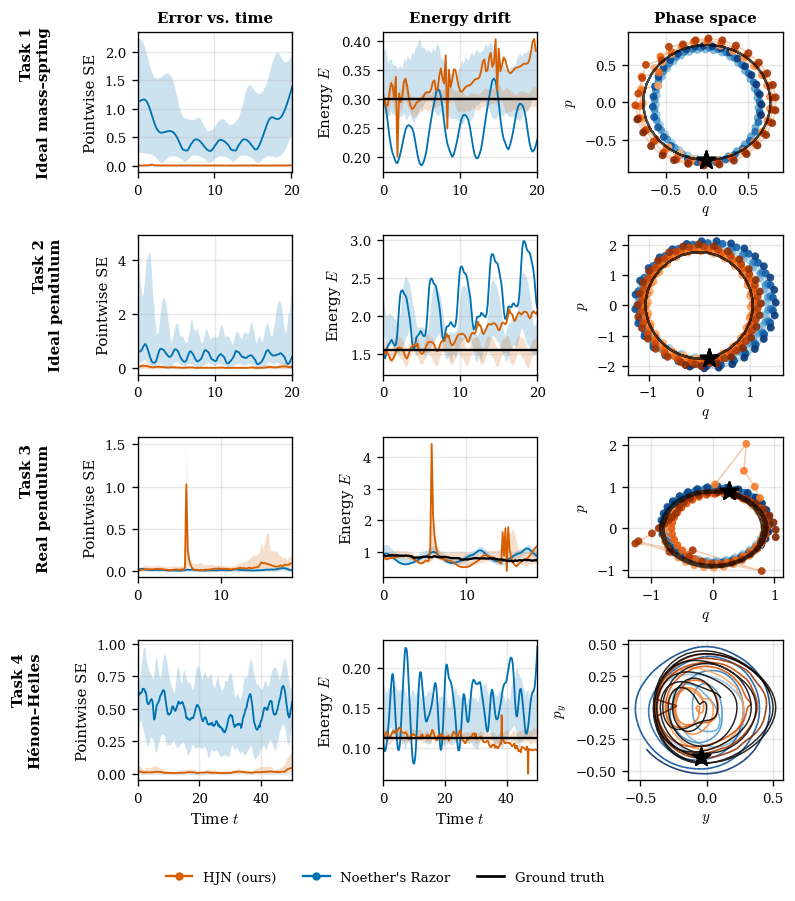

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp2_appendix.pdf


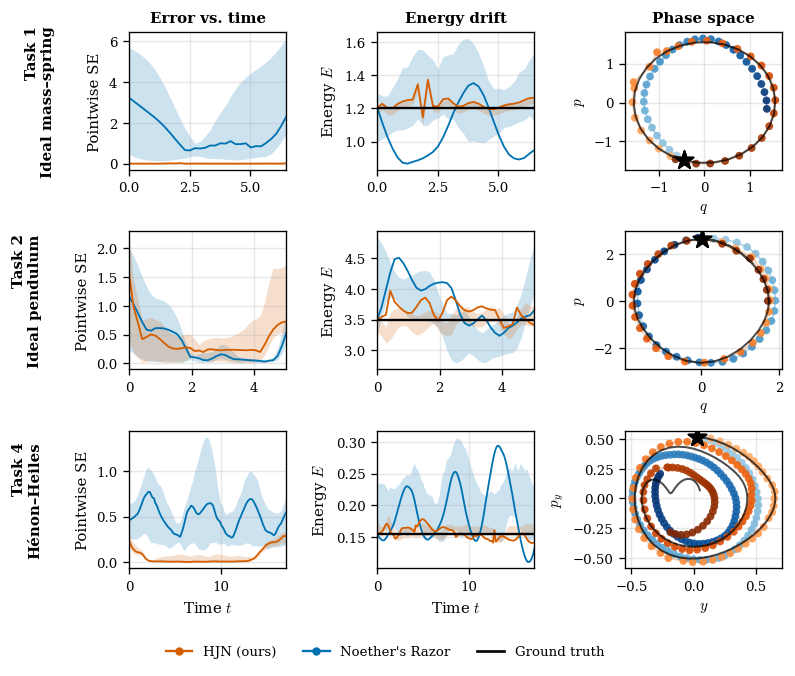

In [13]:
fig2_main, _ = plot_experiment2_grid(EXP2_MAIN_ROWS,
                                     log_error=False, iqr_alpha=0.2,
                                     phase_use_colormap=True)
plt.show()

fig2_app, _ = plot_experiment2_grid(EXP2_APPENDIX_ROWS,
                                    log_error=False, iqr_alpha=0.2,
                                    phase_use_colormap=True)
plt.show()

In [14]:
def print_exp2_numbers():
    rows = [('T1-A', 1, 'multiple_periods'), ('T1-B', 1, 'high_energy'),
            ('T2-A', 2, 'multiple_periods'), ('T2-B', 2, 'high_energy'),
            ('T4-A', 4, 'multiple_periods'), ('T4-B', 4, 'high_energy'),
            ('T3',   3, 'test')]
    print("=" * 78)
    print("EXPERIMENT 2 — single-trajectory diagnostics on the seed-42 representative trajectory")
    print("MSE: median [IQR] across observation choices; energy rel. err.: obs-0 run, %")
    print("HJN per training seed (Task 3: seed 42 only); worst seed = largest value, per metric")
    print("=" * 78)

    def _rel(a, b):
        return ('IQR below Base' if a['q3'] < b['q1'] else
                'IQR above Base' if a['q1'] > b['q3'] else 'IQRs overlap')

    latex, energy_by = [], {}
    for label, t, ds in rows:
        d = EXP2[(t, ds)]
        seeds = EXP2_SEED_RES.get((t, ds), {42: d['HJN']})
        sb = exp2_traj_stats(d['Baseline'])
        eb = exp2_energy_relerr_obs0(d['Baseline'])['rel_pct']
        S = {s: exp2_traj_stats(r) for s, r in seeds.items()}
        E = {s: exp2_energy_relerr_obs0(r)['rel_pct'] for s, r in seeds.items()}
        multi = len(seeds) > 1
        w_mse = max(S, key=lambda s: S[s]['median'])
        w_en = max(E, key=E.get)
        print(f"\n----- {label} (task {t}, {ds}) | traj id={int(d['HJN']['trajectory_id'])} -----")
        for s in seeds:
            fl = ((' <- worst MSE' if multi and s == w_mse else '') +
                  (' <- worst energy' if multi and s == w_en else ''))
            print(f"  HJN seed {s}: MSE median={S[s]['median']:.4f} "
                  f"IQR=[{S[s]['q1']:.4f}, {S[s]['q3']:.4f}] ({_rel(S[s], sb)}) | "
                  f"energy={E[s]:.2f}% ({'below' if E[s] < eb else 'above'} Base){fl}")
        print(f"  Base       : MSE median={sb['median']:.4f} "
              f"IQR=[{sb['q1']:.4f}, {sb['q3']:.4f}] | energy={eb:.2f}%")
        if multi:
            r_mse = sorted(S, key=lambda s: S[s]['median']).index(42) + 1
            r_en = sorted(E, key=E.get).index(42) + 1
            print(f"  displayed seed 42, rank (1 = best): MSE {r_mse}/3, energy {r_en}/3")
            energy_by[(t, ds)] = E
        mse_cells = " & ".join(f"{S[s]['median']:.3f} [{S[s]['q1']:.3f}, {S[s]['q3']:.3f}]"
                               if s in S else "---" for s in EXP2_SEEDS)
        en_cells = " & ".join(f"{E[s]:.1f}" if s in E else "---" for s in EXP2_SEEDS)
        latex.append(f"{label} & {mse_cells} & {sb['median']:.3f} [{sb['q1']:.3f}, {sb['q3']:.3f}] "
                     f"& {en_cells} & {eb:.1f} \\\\")

    print("\n--- Energy error, Test A vs Test B within each task, per seed ---")
    for t in (1, 2, 4):
        for s in EXP2_SEEDS:
            a = energy_by[(t, 'multiple_periods')][s]
            b_ = energy_by[(t, 'high_energy')][s]
            print(f"  task {t} seed {s}: A={a:.2f}%  B={b_:.2f}%  -> B smaller: {b_ < a}")
    six = [v for E in energy_by.values() for v in E.values()]
    print(f"\nHJN energy error over the six settings and all seeds: "
          f"min={min(six):.2f}%, max={max(six):.2f}%")
    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (Task | MSE 42 | 52 | 62 | Base | Energy 42 | 52 | 62 | Base)")
    print("=" * 78)
    print("\n".join(latex))

print_exp2_numbers()

EXPERIMENT 2 — single-trajectory diagnostics on the seed-42 representative trajectory
MSE: median [IQR] across observation choices; energy rel. err.: obs-0 run, %
HJN per training seed (Task 3: seed 42 only); worst seed = largest value, per metric

----- T1-A (task 1, multiple_periods) | traj id=3 -----
  HJN seed 42: MSE median=0.0028 IQR=[0.0021, 0.0041] (IQR below Base) | energy=12.71% (below Base) <- worst energy
  HJN seed 52: MSE median=0.0035 IQR=[0.0026, 0.0047] (IQR below Base) | energy=5.77% (below Base) <- worst MSE
  HJN seed 62: MSE median=0.0023 IQR=[0.0018, 0.0030] (IQR below Base) | energy=5.25% (below Base)
  Base       : MSE median=0.7056 IQR=[0.5496, 0.9223] | energy=18.94%
  displayed seed 42, rank (1 = best): MSE 2/3, energy 3/3

----- T1-B (task 1, high_energy) | traj id=6 -----
  HJN seed 42: MSE median=0.0065 IQR=[0.0044, 0.0089] (IQR below Base) | energy=2.78% (below Base) <- worst MSE
  HJN seed 52: MSE median=0.0035 IQR=[0.0032, 0.0049] (IQR below Base) | ene

In [8]:
VAR_SUB = "variance_results"
# Consistency holds for any system whose (alpha, beta) exist along the flow,
# integrable or not — Task 4 (non-integrable) is included deliberately.
EXP3_TASKS = [(1, 'multiple_periods'), (2, 'multiple_periods'), (4, 'multiple_periods')]

def _var_path(root, task, dataset):
    return root / VAR_SUB / f"task_{task}_variance_results_{dataset}.pkl"

EXP3_SEEDS = (42, 52, 62)
EXP3_DISPLAY_SEED = 42   # panels (a)-(b): the run on which hyperparameters were selected

def _var_path_seed(task, dataset, seed):
    if seed == 42:
        return _var_path(HJN_ROOT, task, dataset)
    return (HJN_ROOT / "seed_results" / f"{VAR_SUB}_seed_{seed}"
            / f"task_{task}_variance_results_{dataset}.pkl")

# reuse Exp 2's representative ids for narrative continuity
EXP3_PREFER_ID = {(1, 'multiple_periods'): 3,
                  (2, 'multiple_periods'): 5,
                  (4, 'multiple_periods'): 57}

EXP3_ROW_LABEL = TASK_LABEL

# colors for the per-quantity traces — deliberately NOT the method colors.
QUANT_COLORS = ['#1B9E77', '#7570B3', '#D95F02', '#E7298A', '#66A61E']

In [9]:
def _rep_index(var_res, prefer_id=None, acc_res=None, strict=True):
    """Return (row_index, trajectory_id, how_selected)."""
    final = var_res['variance_avg'][-1, :]
    ids = None
    if acc_res is not None:
        ids_arr = np.asarray(acc_res['trajectory_ids']).astype(int)
        if len(ids_arr) == var_res['N_traj']:
            ids = ids_arr
    if prefer_id is not None:
        if ids is not None:
            hit = np.where(ids == int(prefer_id))[0]
            if len(hit) == 1:
                return int(hit[0]), int(prefer_id), f'preferred id={prefer_id} (matches Exp 2)'
        if strict:
            raise ValueError(
                f"Exp-3 preferred trajectory id {prefer_id} could not be located "
                f"(ids available: {ids is not None}). The figure caption claims the "
                f"Exp-2 representative is shown, so falling back to a different rule "
                f"would falsify it. Fix the id or pass strict=False deliberately.")
    med = np.nanmedian(final)
    idx = int(np.nanargmin(np.abs(final - med)))
    tid = int(ids[idx]) if ids is not None else None
    return idx, tid, 'closest-to-median full-obs CV'

def _global_cv(curve, eps=1e-3):
    """Per-DOF global-horizon CV. Returns a list of length n."""
    c = _dof2d(np.asarray(curve))                       # (T, n)
    return [float(c[:, i].std(ddof=1) / (abs(c[:, i].mean()) + eps))
            for i in range(c.shape[1])]

def _fmt(vals):
    return ', '.join(f'{v:.3f}' for v in vals)

VAR = {}
for (t, ds) in EXP3_TASKS:
    hs = {s: _load(_var_path_seed(t, ds, s)) for s in EXP3_SEEDS}
    h = hs[EXP3_DISPLAY_SEED]
    b = _load(_var_path(BASE_ROOT, t, ds))
    acc_res = ACC.get(ds, {}).get(t, {}).get('HJN')
    rep, tid, how = _rep_index(h, EXP3_PREFER_ID.get((t, ds)), acc_res)
    worst = max(EXP3_SEEDS, key=lambda s: hs[s]['final_median'])
    VAR[(t, ds)] = {'HJN': h, 'HJN_seeds': hs, 'worst_seed': worst, 'Baseline': b,
                    'rep_idx': rep, 'rep_id': tid, 'rep_how': how}
    if not (0 <= rep < b['N_traj']):
        raise ValueError(f"rep idx {rep} out of range for baseline (N={b['N_traj']})")

print("Exp 3 loaded:")
for (t, ds), d in VAR.items():
    h, b, rep = d['HJN'], d['Baseline'], d['rep_idx']
    print(f"\n--- task{t}/{ds} | rep row={rep} traj_id={d['rep_id']} "
          f"({d['rep_how']}) | N_traj={h['N_traj']} N_obs={h['N_obs']} K_base={b['K']} ---")
    for s, r in d['HJN_seeds'].items():
        flag = '  <- worst' if s == d['worst_seed'] else ''
        print(f"  HJN seed {s} within-seg CV (full obs): median={r['final_median']:.4f} "
              f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]{flag}")
    print(f"  Base within-seg CV (full obs): median={b['final_median']:.4f} "
          f"IQR=[{b['final_q1']:.4f}, {b['final_q3']:.4f}]")
    hq = _global_cv(h['X_final_array'][rep]); hp = _global_cv(h['U_final_array'][rep])
    bc = [_global_cv(b['C_array'][rep, k])[0] for k in range(b['K'])]
    print(f"  rep global-horizon CV  HJN: Q={_fmt(hq)}  P={_fmt(hp)}  "
          f"(expected high — coords reset each Tmax)")
    print(f"  rep global-horizon CV  Base C_k: {_fmt(bc)}  "
          f"(claimed globally invariant — should be LOW if claim holds)")

Exp 3 loaded:

--- task1/multiple_periods | rep row=3 traj_id=3 (preferred id=3 (matches Exp 2)) | N_traj=24 N_obs=97 K_base=3 ---
  HJN seed 42 within-seg CV (full obs): median=0.0135 IQR=[0.0101, 0.0154]
  HJN seed 52 within-seg CV (full obs): median=0.0350 IQR=[0.0266, 0.0883]
  HJN seed 62 within-seg CV (full obs): median=0.0434 IQR=[0.0235, 0.0829]  <- worst
  Base within-seg CV (full obs): median=0.4038 IQR=[0.3841, 0.4338]
  rep global-horizon CV  HJN: Q=0.053  P=0.068  (expected high — coords reset each Tmax)
  rep global-horizon CV  Base C_k: 0.589, 0.465, 0.556  (claimed globally invariant — should be LOW if claim holds)

--- task2/multiple_periods | rep row=5 traj_id=5 (preferred id=5 (matches Exp 2)) | N_traj=20 N_obs=144 K_base=3 ---
  HJN seed 42 within-seg CV (full obs): median=0.0701 IQR=[0.0289, 0.2100]
  HJN seed 52 within-seg CV (full obs): median=0.0145 IQR=[0.0113, 0.0154]
  HJN seed 62 within-seg CV (full obs): median=0.1260 IQR=[0.0789, 0.2561]  <- worst
  Base w

In [8]:
def plot_experiment3_grid(*, rep_id_override=None, log_cv=False,
                          iqr_alpha=0.22, band_alpha=0.22, trace_lw=1.1,
                          other_seed_lw=0.6, save=True, fname=None):
    """
    rep_id_override: dict {(task,dataset): trajectory_id} to force a trajectory.
    Selection (default + any override) is reported via print, not drawn.
    Col 1 shows all 2n learned coordinates: colour = DOF index, solid = Q,
    dashed = P (reduces to a single Q/P pair at n = 1).
    """
    cfg = FIG_CONFIG
    pw = cfg['text_width_in'] / 3.0
    ph = pw * cfg['panel_aspect']
    rows = EXP3_TASKS
    fig, axes = plt.subplots(len(rows), 3, figsize=(3 * pw, len(rows) * ph), squeeze=False)
    COL_HEADERS = ['HJN coords $(Q,P)$', 'Baseline invariants $C_k$',
                   'Within-segment CV']

    sel_report = []

    def _traces(ax, t_arr, curves, names, Tmax, horizon, legend_loc,
                colors=None, styles=None, ncol=None):
        for j, (curve, nm) in enumerate(zip(curves, names)):
            ax.plot(t_arr, curve,
                    styles[j] if styles else '-', lw=trace_lw,
                    color=(colors[j] if colors else QUANT_COLORS[j % len(QUANT_COLORS)]),
                    label=nm)
        m = Tmax
        while m < horizon - 1e-9:
            ax.axvline(m, color='0.4', ls='--', lw=0.7, alpha=0.7)
            m += Tmax
        ax.set_xlim(t_arr[0], t_arr[-1])
        ax.legend(fontsize=cfg['legend_size'] - 1, loc=legend_loc,
                  ncol=(ncol or len(names)), columnspacing=0.8, handlelength=1.2,
                  borderaxespad=0.3, framealpha=0.65)

    for r, (t, ds) in enumerate(rows):
        ax_q, ax_c, ax_v = axes[r]
        d = VAR[(t, ds)]
        h, b = d['HJN'], d['Baseline']

        rep, tid, how = d['rep_idx'], d['rep_id'], d['rep_how']
        if rep_id_override and (t, ds) in rep_id_override:
            want = int(rep_id_override[(t, ds)])
            acc_res = ACC.get(ds, {}).get(t, {}).get('HJN')
            ids = np.asarray(acc_res['trajectory_ids']).astype(int) if acc_res else None
            if ids is not None and len(ids) == h['N_traj'] and (ids == want).sum() == 1:
                rep = int(np.where(ids == want)[0][0]); tid = want; how = 'manual override'
            else:
                warnings.warn(f"override id {want} not found for task{t}/{ds}; keeping default")
        sel_report.append((t, ds, tid, rep, how))

        t_arr = np.asarray(h['t']); Tmax = h['Tmax']; horizon = t_arr[-1]

        # ---- col 1: all 2n learned coordinates ----
        Xr, Ur = _dof2d(h['X_final_array'][rep]), _dof2d(h['U_final_array'][rep])
        nd = Xr.shape[1]
        if nd == 1:
            curves = [Xr[:, 0], Ur[:, 0]]
            names  = ['$Q$', '$P$']
            colors = [QUANT_COLORS[0], QUANT_COLORS[1]]
            styles = ['-', '-']
        else:
            curves = [Xr[:, i] for i in range(nd)] + [Ur[:, i] for i in range(nd)]
            names  = ([f'$Q_{{{i+1}}}$' for i in range(nd)] +
                      [f'$P_{{{i+1}}}$' for i in range(nd)])
            colors = ([QUANT_COLORS[i % len(QUANT_COLORS)] for i in range(nd)] * 2)
            styles = ['-'] * nd + ['--'] * nd
        _traces(ax_q, t_arr, curves, names, Tmax, horizon,
                legend_loc='lower right', colors=colors, styles=styles,
                ncol=min(len(names), 2))
        ax_q.set_ylabel('Learned coord.')

        # ---- col 2: baseline invariants ----
        _traces(ax_c, t_arr, [b['C_array'][rep, k] for k in range(b['K'])],
                [f'$C_{{{k+1}}}$' for k in range(b['K'])], Tmax, horizon,
                legend_loc='lower center', ncol=b['K'])
        ax_c.set_ylabel('Learned invariant')

        # ---- col 3: CV curves; HJN worst seed with IQR, other seeds thin ----
        seeds, w = d['HJN_seeds'], d['worst_seed']
        for s, res in seeds.items():
            if s == w:
                continue
            vm = res['valid_mask']
            ax_v.plot(res['point_counts'][vm], res['median_curve'][vm], '-',
                      lw=other_seed_lw, color=PALETTE['HJN'])
        for m, res in (('HJN', seeds[w]), ('Baseline', b)):
            c = PALETTE[m]; vm = res['valid_mask']
            xp = res['point_counts'][vm]
            ax_v.fill_between(xp, res['p25_curve'][vm], res['p75_curve'][vm],
                              color=c, alpha=band_alpha, lw=0)
            ax_v.plot(xp, res['median_curve'][vm], '-', lw=1.2, color=c)
        if log_cv:
            ax_v.set_yscale('log'); ax_v.set_ylabel('Within-segment CV (log)')
        else:
            ax_v.set_ylabel('Within-segment CV')

        if r == len(rows) - 1:
            ax_q.set_xlabel('Time $t$'); ax_c.set_xlabel('Time $t$')
            ax_v.set_xlabel('Sampled points / traj.')

        ax_q.annotate(EXP3_ROW_LABEL[t], xy=(0, 0.5),
                      xytext=(-ax_q.yaxis.labelpad - 16, 0),
                      xycoords=ax_q.yaxis.label, textcoords='offset points',
                      ha='right', va='center', rotation=90,
                      fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=6)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], lw=1.6,
                      label=f"{METHOD_LABEL['HJN']} (worst seed)"),
               Line2D([0], [0], color=PALETTE['HJN'], lw=other_seed_lw,
                      label=f"{METHOD_LABEL['HJN']} (other seeds)"),
               Line2D([0], [0], color=PALETTE['Baseline'], lw=1.6, label=METHOD_LABEL['Baseline'])]
    fig.legend(handles=handles, loc='lower center', ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=(0.04, 0.04, 1, 1))

    print("Representative trajectory selection (Exp 3):")
    print("  Rule: the Exp-2 representative id (required, not optional).")
    for (t, ds, tid, row, how) in sel_report:
        print(f"  task{t}/{ds}: traj_id={tid} (matrix row {row}) — {how}; "
              f"cols 1-2 seed {EXP3_DISPLAY_SEED}, col 3 worst seed {VAR[(t, ds)]['worst_seed']}")

    if save:
        if fname is None:
            sfx = '_logcv' if log_cv else ''
            fname = FIG_DIR / f"exp3_main{sfx}.pdf"
        fig.savefig(fname); fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, axes

Representative trajectory selection (Exp 3):
  Rule: the Exp-2 representative id (required, not optional).
  task1/multiple_periods: traj_id=3 (matrix row 3) — preferred id=3 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 62
  task2/multiple_periods: traj_id=5 (matrix row 5) — preferred id=5 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 62
  task4/multiple_periods: traj_id=57 (matrix row 6) — preferred id=57 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 42


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp3_main.pdf


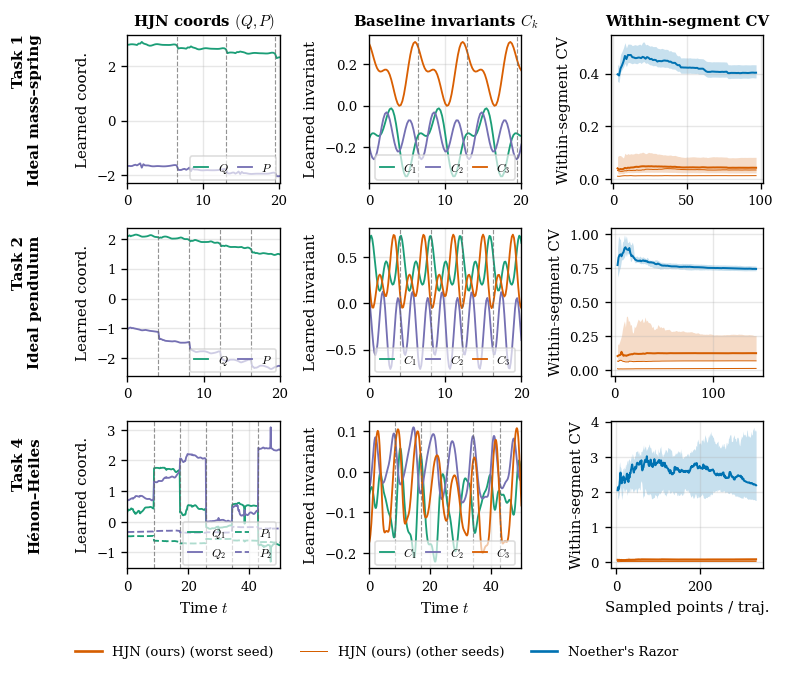

In [9]:
fig3, _ = plot_experiment3_grid(log_cv=False, iqr_alpha=0.22)
plt.show()
# if the CV curves differ by an order of magnitude and squash, try:
# plot_experiment3_grid(log_cv=True)

In [10]:
def print_exp3_numbers():
    print("=" * 78)
    print("EXPERIMENT 3 — within-segment consistency at FULL observation")
    print("median [IQR] over trajectories; HJN per seed, baseline single run")
    print("comparisons with the baseline use HJN's worst seed (largest median)")
    print("=" * 78)
    min_base_q1 = min(VAR[k]['Baseline']['final_q1'] for k in EXP3_TASKS)
    worst_overall, rows = [], []
    for (t, ds) in EXP3_TASKS:
        d = VAR[(t, ds)]
        seeds, w, b = d['HJN_seeds'], d['worst_seed'], d['Baseline']
        for s, r in seeds.items():
            flag = '  <- worst' if s == w else ''
            print(f"  T{t}  HJN seed {s}: median={r['final_median']:.4f}  "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]{flag}")
        print(f"  T{t}  Base (1 run): median={b['final_median']:.4f}  "
              f"IQR=[{b['final_q1']:.4f}, {b['final_q3']:.4f}]")
        meds = {s: r['final_median'] for s, r in seeds.items()}
        rank = sorted(meds, key=meds.get).index(EXP3_DISPLAY_SEED) + 1
        s_q3 = max(seeds, key=lambda s: seeds[s]['final_q3'])
        max_q3 = seeds[s_q3]['final_q3']
        print(f"    seed spread of medians (max/min): {max(meds.values()) / min(meds.values()):.2f}; "
              f"seed {EXP3_DISPLAY_SEED} rank {rank}/{len(seeds)} (1 = lowest CV)")
        print(f"    ratio of medians, Base / worst HJN seed: {b['final_median'] / meds[w]:.1f}")
        print(f"    largest HJN Q3: {max_q3:.4f} (seed {s_q3}) vs Base Q1 {b['final_q1']:.4f} "
              f"-> below it: {max_q3 < b['final_q1']}; below lowest Base Q1 on any task "
              f"({min_base_q1:.4f}): {max_q3 < min_base_q1}")
        for s, r in seeds.items():
            vm = r['valid_mask'] & b['valid_mask']
            below = bool(np.all(r['median_curve'][vm] < b['median_curve'][vm]))
            print(f"    seed {s}: HJN median curve below Base at every subset size "
                  f"(from {r['point_counts'][vm][0]} pts): {below}")
        worst_overall.append((meds[w], t, w))
        n_s = len(seeds)
        for i, (s, r) in enumerate(seeds.items()):
            c_task = f"\\multirow{{{n_s}}}{{*}}{{T{t}-A}}" if i == 0 else ""
            c_base = (f"\\multirow{{{n_s}}}{{*}}{{{b['final_median']:.3f} "
                      f"[{b['final_q1']:.3f}, {b['final_q3']:.3f}]}}" if i == 0 else "")
            rows.append(f"{c_task} & {s} & {r['final_median']:.3f} "
                        f"[{r['final_q1']:.3f}, {r['final_q3']:.3f}] & {c_base} \\\\")
        rows.append("\\midrule")
        print()
    m, t, s = max(worst_overall)
    print(f"Largest HJN median over all tasks and seeds: {m:.4f} (T{t}, seed {s})")
    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (Task | Seed | HJN CV | Base CV); needs \\usepackage{multirow}")
    print("=" * 78)
    print("\n".join(rows[:-1]))

print_exp3_numbers()

EXPERIMENT 3 — within-segment consistency at FULL observation
median [IQR] over trajectories; HJN per seed, baseline single run
comparisons with the baseline use HJN's worst seed (largest median)
  T1  HJN seed 42: median=0.0135  IQR=[0.0101, 0.0154]
  T1  HJN seed 52: median=0.0350  IQR=[0.0266, 0.0883]
  T1  HJN seed 62: median=0.0434  IQR=[0.0235, 0.0829]  <- worst
  T1  Base (1 run): median=0.4038  IQR=[0.3841, 0.4338]
    seed spread of medians (max/min): 3.22; seed 42 rank 1/3 (1 = lowest CV)
    ratio of medians, Base / worst HJN seed: 9.3
    largest HJN Q3: 0.0883 (seed 52) vs Base Q1 0.3841 -> below it: True; below lowest Base Q1 on any task (0.3841): True
    seed 42: HJN median curve below Base at every subset size (from 3 pts): True
    seed 52: HJN median curve below Base at every subset size (from 3 pts): True
    seed 62: HJN median curve below Base at every subset size (from 3 pts): True

  T2  HJN seed 42: median=0.0701  IQR=[0.0289, 0.2100]
  T2  HJN seed 52: median=

-----------------------------------------

HIGH ENERGY

----------------------------------------------------------

In [10]:
# ======================= Exp 3, Test B (high_energy) =======================
# Reuses from the Test A cells: EXP3_SEEDS, EXP3_DISPLAY_SEED, _var_path,
# _var_path_seed, _rep_index, _global_cv, _fmt, EXP3_ROW_LABEL, QUANT_COLORS.
EXP3B_TASKS = [(1, 'high_energy'), (2, 'high_energy'), (4, 'high_energy')]

# Exp-2 representative ids for Test B (same rule as EXP3_PREFER_ID for Test A)
EXP3B_PREFER_ID = {(1, 'high_energy'): 6,
                   (2, 'high_energy'): 13,
                   (4, 'high_energy'): 10}

if 'EXPECTED_REP_ID' in globals():
    for _k, _v in EXP3B_PREFER_ID.items():
        if EXPECTED_REP_ID.get(_k) != _v:
            raise ValueError(f"EXP3B_PREFER_ID{_k}={_v} disagrees with "
                             f"EXPECTED_REP_ID{_k}={EXPECTED_REP_ID.get(_k)}")
    print("EXP3B_PREFER_ID agrees with Exp 2's EXPECTED_REP_ID.")

EXP3B_PREFER_ID agrees with Exp 2's EXPECTED_REP_ID.


In [11]:
def _build_exp3b():
    out = {}
    for (t, ds) in EXP3B_TASKS:
        hs = {s: _load(_var_path_seed(t, ds, s)) for s in EXP3_SEEDS}
        h = hs[EXP3_DISPLAY_SEED]
        b = _load(_var_path(BASE_ROOT, t, ds))
        acc_h = ACC.get(ds, {}).get(t, {}).get('HJN')
        acc_b = ACC.get(ds, {}).get(t, {}).get('Baseline')
        # HJN and baseline rows must refer to the same trajectories (checked in Step 1)
        if acc_h is not None and acc_b is not None:
            if not np.array_equal(np.asarray(acc_h['trajectory_ids']).astype(int),
                                  np.asarray(acc_b['trajectory_ids']).astype(int)):
                raise ValueError(f"task{t}/{ds}: HJN and baseline trajectory orders differ")
        rep, tid, how = _rep_index(h, EXP3B_PREFER_ID.get((t, ds)), acc_h)   # strict
        worst = max(EXP3_SEEDS, key=lambda s: hs[s]['final_median'])
        if not (0 <= rep < b['N_traj']):
            raise ValueError(f"rep idx {rep} out of range for baseline (N={b['N_traj']})")
        out[(t, ds)] = {'HJN': h, 'HJN_seeds': hs, 'worst_seed': worst, 'Baseline': b,
                        'rep_idx': rep, 'rep_id': tid, 'rep_how': how}
    return out

def _report_exp3b(var):
    print("Exp 3 (Test B) loaded:")
    for (t, ds), d in var.items():
        h, b, rep = d['HJN'], d['Baseline'], d['rep_idx']
        print(f"\n--- task{t}/{ds} | rep row={rep} traj_id={d['rep_id']} "
              f"({d['rep_how']}) | N_traj={h['N_traj']} N_obs={h['N_obs']} K_base={b['K']} ---")
        for s, r in d['HJN_seeds'].items():
            flag = '  <- worst' if s == d['worst_seed'] else ''
            print(f"  HJN seed {s} within-seg CV (full obs): median={r['final_median']:.4f} "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]{flag}")
        print(f"  Base within-seg CV (full obs): median={b['final_median']:.4f} "
              f"IQR=[{b['final_q1']:.4f}, {b['final_q3']:.4f}]")
        hq = _global_cv(h['X_final_array'][rep]); hp = _global_cv(h['U_final_array'][rep])
        bc = [_global_cv(b['C_array'][rep, k])[0] for k in range(b['K'])]
        print(f"  rep global-horizon CV  HJN: Q={_fmt(hq)}  P={_fmt(hp)}  "
              f"(expected high when the horizon spans >1 segment)")
        print(f"  rep global-horizon CV  Base C_k: {_fmt(bc)}")

VAR_B = _build_exp3b()
_report_exp3b(VAR_B)

Exp 3 (Test B) loaded:

--- task1/high_energy | rep row=0 traj_id=6 (preferred id=6 (matches Exp 2)) | N_traj=25 N_obs=32 K_base=3 ---
  HJN seed 42 within-seg CV (full obs): median=0.0565 IQR=[0.0313, 0.0731]
  HJN seed 52 within-seg CV (full obs): median=0.1080 IQR=[0.0656, 0.3390]  <- worst
  HJN seed 62 within-seg CV (full obs): median=0.0993 IQR=[0.0526, 0.1553]
  Base within-seg CV (full obs): median=0.4145 IQR=[0.4059, 0.4201]
  rep global-horizon CV  HJN: Q=0.021  P=0.019  (expected high when the horizon spans >1 segment)
  rep global-horizon CV  Base C_k: 0.411, 0.462, 0.380

--- task2/high_energy | rep row=2 traj_id=13 (preferred id=13 (matches Exp 2)) | N_traj=13 N_obs=37 K_base=3 ---
  HJN seed 42 within-seg CV (full obs): median=0.2143 IQR=[0.1113, 0.4318]
  HJN seed 52 within-seg CV (full obs): median=0.0297 IQR=[0.0174, 0.0454]
  HJN seed 62 within-seg CV (full obs): median=0.2799 IQR=[0.1426, 0.4937]  <- worst
  Base within-seg CV (full obs): median=0.5400 IQR=[0.5026, 

Representative trajectory selection (Exp 3, Test B):
  Rule: the Exp-2 representative id (required, not optional).
  task1/high_energy: traj_id=6 (matrix row 0) — preferred id=6 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 52
  task2/high_energy: traj_id=13 (matrix row 2) — preferred id=13 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 62
  task4/high_energy: traj_id=10 (matrix row 10) — preferred id=10 (matches Exp 2); cols 1-2 seed 42, col 3 worst seed 62


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp3_high_energy.pdf
saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp3_high_energy.png


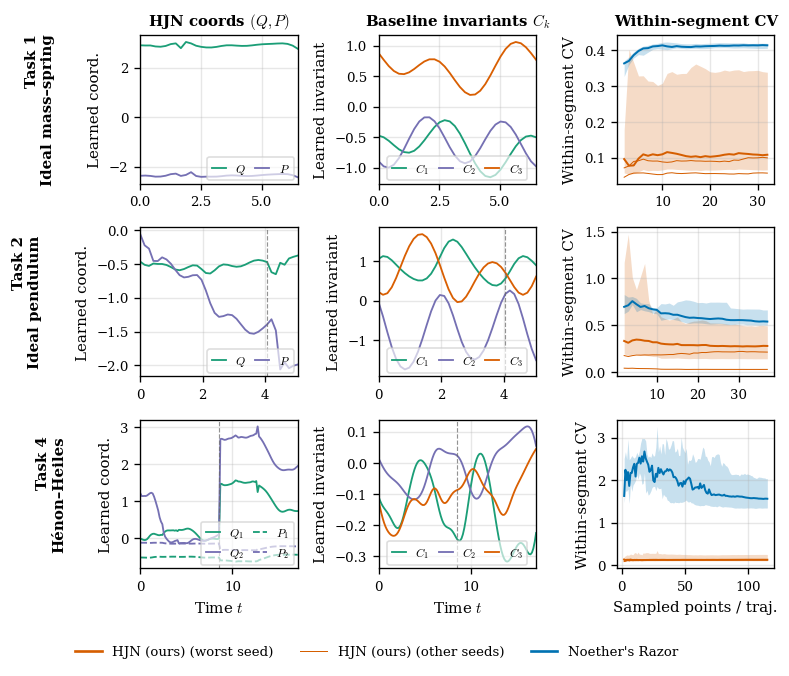

In [ ]:
def plot_experiment3_grid_B(*, var=None, tasks=None, rep_id_override=None, log_cv=False,
                            iqr_alpha=0.22, band_alpha=0.22, trace_lw=1.1,
                            other_seed_lw=0.6, save=False, fname=None, overwrite=False):
    """
    Test-B copy of plot_experiment3_grid; drawing code unchanged.
    Differences: reads `var`/`tasks` (default VAR_B / EXP3B_TASKS) instead of the
    Test-A globals; save=False by default; refuses to write over an existing file
    unless overwrite=True, and refuses any exp3_main* name outright.
    """
    var = VAR_B if var is None else var
    tasks = EXP3B_TASKS if tasks is None else tasks
    cfg = FIG_CONFIG
    pw = cfg['text_width_in'] / 3.0
    ph = pw * cfg['panel_aspect']
    rows = tasks
    fig, axes = plt.subplots(len(rows), 3, figsize=(3 * pw, len(rows) * ph), squeeze=False)
    COL_HEADERS = ['HJN coords $(Q,P)$', 'Baseline invariants $C_k$',
                   'Within-segment CV']
    sel_report = []

    def _traces(ax, t_arr, curves, names, Tmax, horizon, legend_loc,
                colors=None, styles=None, ncol=None):
        for j, (curve, nm) in enumerate(zip(curves, names)):
            ax.plot(t_arr, curve,
                    styles[j] if styles else '-', lw=trace_lw,
                    color=(colors[j] if colors else QUANT_COLORS[j % len(QUANT_COLORS)]),
                    label=nm)
        m = Tmax
        while m < horizon - 1e-9:
            ax.axvline(m, color='0.4', ls='--', lw=0.7, alpha=0.7)
            m += Tmax
        ax.set_xlim(t_arr[0], t_arr[-1])
        ax.legend(fontsize=cfg['legend_size'] - 1, loc=legend_loc,
                  ncol=(ncol or len(names)), columnspacing=0.8, handlelength=1.2,
                  borderaxespad=0.3, framealpha=0.65)

    for r, (t, ds) in enumerate(rows):
        ax_q, ax_c, ax_v = axes[r]
        d = var[(t, ds)]
        h, b = d['HJN'], d['Baseline']

        rep, tid, how = d['rep_idx'], d['rep_id'], d['rep_how']
        if rep_id_override and (t, ds) in rep_id_override:
            want = int(rep_id_override[(t, ds)])
            acc_res = ACC.get(ds, {}).get(t, {}).get('HJN')
            ids = np.asarray(acc_res['trajectory_ids']).astype(int) if acc_res else None
            if ids is not None and len(ids) == h['N_traj'] and (ids == want).sum() == 1:
                rep = int(np.where(ids == want)[0][0]); tid = want; how = 'manual override'
            else:
                warnings.warn(f"override id {want} not found for task{t}/{ds}; keeping default")
        sel_report.append((t, ds, tid, rep, how))

        t_arr = np.asarray(h['t']); Tmax = h['Tmax']; horizon = t_arr[-1]

        # ---- col 1: all 2n learned coordinates ----
        Xr, Ur = _dof2d(h['X_final_array'][rep]), _dof2d(h['U_final_array'][rep])
        nd = Xr.shape[1]
        if nd == 1:
            curves = [Xr[:, 0], Ur[:, 0]]
            names  = ['$Q$', '$P$']
            colors = [QUANT_COLORS[0], QUANT_COLORS[1]]
            styles = ['-', '-']
        else:
            curves = [Xr[:, i] for i in range(nd)] + [Ur[:, i] for i in range(nd)]
            names  = ([f'$Q_{{{i+1}}}$' for i in range(nd)] +
                      [f'$P_{{{i+1}}}$' for i in range(nd)])
            colors = ([QUANT_COLORS[i % len(QUANT_COLORS)] for i in range(nd)] * 2)
            styles = ['-'] * nd + ['--'] * nd
        _traces(ax_q, t_arr, curves, names, Tmax, horizon,
                legend_loc='lower right', colors=colors, styles=styles,
                ncol=min(len(names), 2))
        ax_q.set_ylabel('Learned coord.')

        # ---- col 2: baseline invariants ----
        _traces(ax_c, t_arr, [b['C_array'][rep, k] for k in range(b['K'])],
                [f'$C_{{{k+1}}}$' for k in range(b['K'])], Tmax, horizon,
                legend_loc='lower center', ncol=b['K'])
        ax_c.set_ylabel('Learned invariant')

        # ---- col 3: CV curves; HJN worst seed with IQR, other seeds thin ----
        seeds, w = d['HJN_seeds'], d['worst_seed']
        for s, res in seeds.items():
            if s == w:
                continue
            vm = res['valid_mask']
            ax_v.plot(res['point_counts'][vm], res['median_curve'][vm], '-',
                      lw=other_seed_lw, color=PALETTE['HJN'])
        for m, res in (('HJN', seeds[w]), ('Baseline', b)):
            c = PALETTE[m]; vm = res['valid_mask']
            xp = res['point_counts'][vm]
            ax_v.fill_between(xp, res['p25_curve'][vm], res['p75_curve'][vm],
                              color=c, alpha=band_alpha, lw=0)
            ax_v.plot(xp, res['median_curve'][vm], '-', lw=1.2, color=c)
        if log_cv:
            ax_v.set_yscale('log'); ax_v.set_ylabel('Within-segment CV (log)')
        else:
            ax_v.set_ylabel('Within-segment CV')

        if r == len(rows) - 1:
            ax_q.set_xlabel('Time $t$'); ax_c.set_xlabel('Time $t$')
            ax_v.set_xlabel('Sampled points / traj.')

        ax_q.annotate(EXP3_ROW_LABEL[t], xy=(0, 0.5),
                      xytext=(-ax_q.yaxis.labelpad - 16, 0),
                      xycoords=ax_q.yaxis.label, textcoords='offset points',
                      ha='right', va='center', rotation=90,
                      fontsize=cfg['font_size'], fontweight='bold')

    for c_idx, head in enumerate(COL_HEADERS):
        axes[0][c_idx].set_title(head, fontweight='bold', pad=6)

    handles = [Line2D([0], [0], color=PALETTE['HJN'], lw=1.6,
                      label=f"{METHOD_LABEL['HJN']} (worst seed)"),
               Line2D([0], [0], color=PALETTE['HJN'], lw=other_seed_lw,
                      label=f"{METHOD_LABEL['HJN']} (other seeds)"),
               Line2D([0], [0], color=PALETTE['Baseline'], lw=1.6, label=METHOD_LABEL['Baseline'])]
    fig.legend(handles=handles, loc='lower center', ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0.04, 0.04, 1, 1))

    print("Representative trajectory selection (Exp 3, Test B):")
    print("  Rule: the Exp-2 representative id (required, not optional).")
    for (t, ds, tid, row, how) in sel_report:
        print(f"  task{t}/{ds}: traj_id={tid} (matrix row {row}) — {how}; "
              f"cols 1-2 seed {EXP3_DISPLAY_SEED}, col 3 worst seed {var[(t, ds)]['worst_seed']}")

    # ---- saving: explicit opt-in, never over Test A figures or existing files ----
    if fname is None:
        fname = FIG_DIR / f"exp3_high_energy{'_logcv' if log_cv else ''}.pdf"
    targets = [Path(fname).with_suffix('.pdf'), Path(fname).with_suffix('.png')]
    if save:
        if any(p.name.startswith('exp3_main') for p in targets):
            raise ValueError("Refusing to write to an exp3_main* name (Test A figure).")
        existing = [str(p) for p in targets if p.exists()]
        if existing and not overwrite:
            raise FileExistsError(f"Would overwrite {existing}; pass overwrite=True to allow.")
        for p in targets:
            fig.savefig(p)
            print(f"saved: {p}")
    else:
        print("Not saved (save=False). save=True would write:\n  " +
              "\n  ".join(map(str, targets)))
    return fig, axes

fig3b, _ = plot_experiment3_grid_B(log_cv=False, save=True)   
plt.show()


In [13]:
def print_exp3b_numbers():
    var, tasks = VAR_B, EXP3B_TASKS
    var_a = globals().get('VAR')                    # Test A results, for comparison only
    print("=" * 78)
    print("EXPERIMENT 3, TEST B (energy extrapolation): within-segment consistency at FULL observation")
    print("median [IQR] over trajectories; HJN per seed, baseline single run")
    print("comparisons with the baseline use HJN's worst seed (largest median)")
    print("=" * 78)
    min_base_q1 = min(var[k]['Baseline']['final_q1'] for k in tasks)
    min_base_q1_all = (min(min_base_q1, min(v['Baseline']['final_q1'] for v in var_a.values()))
                       if var_a else None)
    worst_overall, rows = [], []
    for (t, ds) in tasks:
        d = var[(t, ds)]
        seeds, w, b = d['HJN_seeds'], d['worst_seed'], d['Baseline']
        for s, r in seeds.items():
            flag = '  <- worst' if s == w else ''
            print(f"  T{t}  HJN seed {s}: median={r['final_median']:.4f}  "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]{flag}")
        print(f"  T{t}  Base (1 run): median={b['final_median']:.4f}  "
              f"IQR=[{b['final_q1']:.4f}, {b['final_q3']:.4f}]")
        meds = {s: r['final_median'] for s, r in seeds.items()}
        rank = sorted(meds, key=meds.get).index(EXP3_DISPLAY_SEED) + 1
        s_q3 = max(seeds, key=lambda s: seeds[s]['final_q3'])
        max_q3 = seeds[s_q3]['final_q3']
        print(f"    seed spread of medians (max/min): {max(meds.values()) / min(meds.values()):.2f}; "
              f"seed {EXP3_DISPLAY_SEED} rank {rank}/{len(seeds)} (1 = lowest CV)")
        print(f"    ratio of medians, Base / worst HJN seed: {b['final_median'] / meds[w]:.1f}")
        print(f"    largest HJN Q3: {max_q3:.4f} (seed {s_q3}) vs Base Q1 {b['final_q1']:.4f} "
              f"-> below it: {max_q3 < b['final_q1']}; below lowest Base Q1 on any Test-B task "
              f"({min_base_q1:.4f}): {max_q3 < min_base_q1}")
        if min_base_q1_all is not None:
            print(f"    ... below lowest Base Q1 over all six settings "
                  f"({min_base_q1_all:.4f}): {max_q3 < min_base_q1_all}")
        for s, r in seeds.items():
            vm = r['valid_mask'] & b['valid_mask']
            below = bool(np.all(r['median_curve'][vm] < b['median_curve'][vm]))
            print(f"    seed {s}: HJN median curve below Base at every subset size "
                  f"(from {r['point_counts'][vm][0]} pts): {below}")
        # paired, per-trajectory (rows aligned; verified in Step 1)
        bf = b['variance_avg'][-1]
        for s, r in seeds.items():
            hf = r['variance_avg'][-1]
            print(f"    seed {s}: trajectories with HJN CV < Base CV at full obs: "
                  f"{int(np.sum(hf < bf))}/{len(bf)}")
        # Test A -> Test B change
        a = var_a.get((t, 'multiple_periods')) if var_a else None
        if a is not None:
            ch = ", ".join(
                f"s{s} {a['HJN_seeds'][s]['final_median']:.3f}->{r['final_median']:.3f} "
                f"(x{r['final_median'] / a['HJN_seeds'][s]['final_median']:.2f})"
                for s, r in seeds.items())
            print(f"    Test A -> B medians: HJN {ch}")
            print(f"                         Base {a['Baseline']['final_median']:.3f}->"
                  f"{b['final_median']:.3f} (x{b['final_median'] / a['Baseline']['final_median']:.2f}); "
                  f"worst seed A={a['worst_seed']} B={w}")
        worst_overall.append((meds[w], t, w))
        n_s = len(seeds)
        for i, (s, r) in enumerate(seeds.items()):
            c_task = f"\\multirow{{{n_s}}}{{*}}{{T{t}-B}}" if i == 0 else ""
            c_base = (f"\\multirow{{{n_s}}}{{*}}{{{b['final_median']:.3f} "
                      f"[{b['final_q1']:.3f}, {b['final_q3']:.3f}]}}" if i == 0 else "")
            rows.append(f"{c_task} & {s} & {r['final_median']:.3f} "
                        f"[{r['final_q1']:.3f}, {r['final_q3']:.3f}] & {c_base} \\\\")
        rows.append("\\midrule")
        print()
    m, t, s = max(worst_overall)
    print(f"Largest HJN median over Test-B tasks and seeds: {m:.4f} (T{t}, seed {s})")
    print("=" * 78)
    print("PASTE-READY LaTeX ROWS (Task | Seed | HJN CV | Base CV); needs \\usepackage{multirow}")
    print("=" * 78)
    print("\n".join(rows[:-1]))

print_exp3b_numbers()

EXPERIMENT 3, TEST B (energy extrapolation): within-segment consistency at FULL observation
median [IQR] over trajectories; HJN per seed, baseline single run
comparisons with the baseline use HJN's worst seed (largest median)
  T1  HJN seed 42: median=0.0565  IQR=[0.0313, 0.0731]
  T1  HJN seed 52: median=0.1080  IQR=[0.0656, 0.3390]  <- worst
  T1  HJN seed 62: median=0.0993  IQR=[0.0526, 0.1553]
  T1  Base (1 run): median=0.4145  IQR=[0.4059, 0.4201]
    seed spread of medians (max/min): 1.91; seed 42 rank 1/3 (1 = lowest CV)
    ratio of medians, Base / worst HJN seed: 3.8
    largest HJN Q3: 0.3390 (seed 52) vs Base Q1 0.4059 -> below it: True; below lowest Base Q1 on any Test-B task (0.4059): True
    ... below lowest Base Q1 over all six settings (0.3841): True
    seed 42: HJN median curve below Base at every subset size (from 2 pts): True
    seed 52: HJN median curve below Base at every subset size (from 2 pts): True
    seed 62: HJN median curve below Base at every subset siz

In [15]:
for _lbl, _var, _tasks in (('A', VAR, EXP3_TASKS), ('B', VAR_B, EXP3B_TASKS)):
    for (_t, _ds) in _tasks:
        _d = _var[(_t, _ds)]; _b = _d['Baseline']
        for _s, _r in _d['HJN_seeds'].items():
            _vm = _r['valid_mask'] & _b['valid_mask']; _pc = _r['point_counts'][_vm]
            _f = lambda a: 'none' if len(a) == 0 else f"{len(a)} counts, {a.min()}-{a.max()}"
            print(f"T{_t}-{_lbl} s{_s}{' (worst)' if _s == _d['worst_seed'] else ''}: "
                  f"median<Base median everywhere: {bool(np.all(_r['median_curve'][_vm] < _b['median_curve'][_vm]))} | "
                  f"HJN Q3>Base median at: {_f(_pc[_r['p75_curve'][_vm] > _b['median_curve'][_vm]])} | "
                  f"HJN Q3>Base Q1 at: {_f(_pc[_r['p75_curve'][_vm] > _b['p25_curve'][_vm]])}")

T1-A s42: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T1-A s52: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T1-A s62 (worst): median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T2-A s42: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T2-A s52: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T2-A s62 (worst): median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T4-A s42 (worst): median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T4-A s52: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T4-A s62: median<Base median everywhere: True | HJN Q3>Base median at: none | HJN Q3>Base Q1 at: none
T1-B s42: median<Base median everywhere: True | HJN Q3>Bas

In [1]:
# =============================================================================
# Within-segment constancy experiment: paper tables and pre-committed comparisons.
# Read-only (files opened with "rb"); prints only.
# =============================================================================
import os
import pickle
import pandas as pd

BASE = "/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN"
TASKS = {"task_1": "Task 1", "task_2": "Task 2", "task_4": "Task 4"}
MAIN_DIRS = {
    "42": "constancy_results",
    "52": os.path.join("seed_results", "constancy_results_seed_52"),
    "62": os.path.join("seed_results", "constancy_results_seed_62"),
}
SEEDS = list(MAIN_DIRS)
SETS = ("Train", "TestA", "TestB")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


def _load(rel):
    with open(os.path.join(BASE, rel), "rb") as f:
        return pickle.load(f)


R = {(task, seed): _load(os.path.join(folder, f"{task}_constancy_results.pkl"))
     for task in TASKS for seed, folder in MAIN_DIRS.items()}


def summ(task, m, st):
    return R[(task, m)]["sets"][st]["summary"]


def med(task, m, st, metric):
    return summ(task, m, st)[metric]["median"]


def cell(task, m, st, metric):
    s = summ(task, m, st)[metric]
    return f"{s['median']:.3g} [{s['q25']:.3g}, {s['q75']:.3g}]"


def nref(task, m):
    return R[(task, m)]["spec"]["noise_ref"]


def hdr(s):
    print("\n" + "=" * 110 + "\n" + s + "\n" + "=" * 110)


def show(rows):
    print(pd.DataFrame(rows).to_string(index=False))


# ----------------------------------------------------------------------------- 0
hdr("0. Provenance (which file is which; counts quoted in captions)")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        r = R[(task, m)]
        rows.append({"task": lab, "seed": m, "Tmax": r["spec"]["Tmax"], "sigma2": r["spec"]["sigma2"],
                     "noise_ref": round(r["spec"]["noise_ref"], 4),
                     **{f"{st} traj/seg": f"{summ(task, m, st)['n_traj']}/{summ(task, m, st)['n_segments']}"
                        for st in SETS},
                     "model sha256": r["model_sha256"][:12],
                     "outputs sha256": r["hashes"]["all_outputs"][:12]})
show(rows)
for task, lab in TASKS.items():
    hashes = [R[(task, m)]["model_sha256"] for m in SEEDS]
    print(f"{lab}: distinct models in every file: {len(set(hashes)) == len(hashes)}")

# ----------------------------------------------------------------------------- 1
hdr("1. MAIN TEXT TABLE - D0, median [IQR] over trajectories (Train and Test A adjacent); last column W0max at Test A")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        rows.append({"task": lab, "seed": m,
                     "D0 Train": cell(task, m, "Train", "D0"),
                     "D0 Test A": cell(task, m, "TestA", "D0"),
                     "D0 Test B": cell(task, m, "TestB", "D0"),
                     "W0max Test A": cell(task, m, "TestA", "W0max")})
show(rows)

# ----------------------------------------------------------------------------- 2
hdr("2. APPENDIX - W0max, median [IQR] over trajectories, and maximum over trajectories")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        row = {"task": lab, "seed": m}
        for st in SETS:
            row[f"W0max {st}"] = cell(task, m, st, "W0max")
            row[f"max {st}"] = f"{summ(task, m, st)['W0max']['max']:.3g}"
        rows.append(row)
show(rows)

# ----------------------------------------------------------------------------- 3
hdr("3. APPENDIX - absolute deviations (phase-space units) vs noise reference sigma*sqrt(2n), with the t'=0 floor")
for st in SETS:
    print(f"\n--- {st}")
    rows = []
    for task, lab in TASKS.items():
        for m in SEEDS:
            s = summ(task, m, st)
            rows.append({"task": lab, "seed": m,
                         "rms|delta|": cell(task, m, st, "rms_delta"),
                         "max|delta|": cell(task, m, st, "max_delta"),
                         "rms|disp|": cell(task, m, st, "rms_disp"),
                         "noise ref": f"{nref(task, m):.4f}",
                         "med rms|delta| / ref": f"{s['rms_delta']['median'] / nref(task, m):.3g}",
                         "med max|delta| / ref": f"{s['max_delta']['median'] / nref(task, m):.3g}",
                         "floor max": f"{s['floor_t0_max']:.2e}",
                         "floor rms": f"{s['floor_t0_rms']:.2e}",
                         "min rms|delta|": f"{s['min_rms_delta']:.3g}",
                         "min rms|delta| / floor max": f"{s['min_rms_delta'] / s['floor_t0_max']:.3g}"})
    show(rows)

# ----------------------------------------------------------------------------- 4
hdr("4. PRE-COMMITTED READING NUMBERS - median rms|delta| / noise ref, and median D0 / median D0(Train)")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        rows.append({"task": lab, "seed": m,
                     **{f"noise ratio {st}": f"{med(task, m, st, 'rms_delta') / nref(task, m):.3g}" for st in SETS},
                     **{f"D0/Train {st}": f"{med(task, m, st, 'D0') / med(task, m, 'Train', 'D0'):.3g}"
                        for st in ("TestA", "TestB")}})
show(rows)
print("\n'Within the training-noise scale' (median rms|delta| < noise ref) for ALL three seeds:")
for task, lab in TASKS.items():
    print(f"  {lab}: " + " | ".join(
        f"{st} {all(med(task, m, st, 'rms_delta') < nref(task, m) for m in SEEDS)}" for st in SETS))

# ----------------------------------------------------------------------------- 5
hdr("5. TRAIN -> TEST A (primary reading of the held-out effect); ratios of medians, Test A / Train")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        a, t = summ(task, m, "TestA"), summ(task, m, "Train")
        rows.append({"task": lab, "seed": m,
                     "D0": f"{a['D0']['median'] / t['D0']['median']:.3g}",
                     "W0max": f"{a['W0max']['median'] / t['W0max']['median']:.3g}",
                     "rms|delta|": f"{a['rms_delta']['median'] / t['rms_delta']['median']:.3g}",
                     "max|delta|": f"{a['max_delta']['median'] / t['max_delta']['median']:.3g}",
                     "rms|disp| (motion)": f"{a['rms_disp']['median'] / t['rms_disp']['median']:.3g}",
                     "D0 IQRs overlap": bool(a["D0"]["q25"] <= t["D0"]["q75"] and t["D0"]["q25"] <= a["D0"]["q75"])})
show(rows)

# ----------------------------------------------------------------------------- 6
hdr("6. TEST B (descriptive; ratios read together with absolute deviations and motion); ratios of medians")
rows = []
for task, lab in TASKS.items():
    for m in SEEDS:
        b, a, t = summ(task, m, "TestB"), summ(task, m, "TestA"), summ(task, m, "Train")
        rows.append({"task": lab, "seed": m,
                     "D0 B/A": f"{b['D0']['median'] / a['D0']['median']:.3g}",
                     "rms|delta| B/A": f"{b['rms_delta']['median'] / a['rms_delta']['median']:.3g}",
                     "rms|disp| B/A": f"{b['rms_disp']['median'] / a['rms_disp']['median']:.3g}",
                     "D0 B/Train": f"{b['D0']['median'] / t['D0']['median']:.3g}",
                     "rms|delta| B/Train": f"{b['rms_delta']['median'] / t['rms_delta']['median']:.3g}",
                     "rms|disp| B/Train": f"{b['rms_disp']['median'] / t['rms_disp']['median']:.3g}",
                     "noise ratio B": f"{b['rms_delta']['median'] / nref(task, m):.3g}",
                     "W0max max over traj B": f"{b['W0max']['max']:.3g}"})
show(rows)

# ----------------------------------------------------------------------------- 7
hdr("7. ACROSS SEEDS (variability across training runs; not attribution)")
rows = []
for task, lab in TASKS.items():
    for st in SETS:
        for metric in ("D0", "W0max", "rms_delta"):
            v = {m: med(task, m, st, metric) for m in SEEDS}
            lo, hi = min(v.values()), max(v.values())
            rows.append({"task": lab, "set": st, "metric": metric,
                         **{f"seed {m}": f"{v[m]:.3g}" for m in SEEDS},
                         "min": f"{lo:.3g}", "max": f"{hi:.3g}", "max/min": f"{hi / lo:.3g}"})
show(rows)

print("\nAcross-task comparisons are not made (procedure, Step 14), so none are printed.")


0. Provenance (which file is which; counts quoted in captions)
  task seed     Tmax  sigma2  noise_ref Train traj/seg TestA traj/seg TestB traj/seg model sha256 outputs sha256
Task 1   42 6.492625  0.1000     0.4472          24/24          24/96          25/25 ea153cbc02be   494c8dad5809
Task 1   52 6.492625  0.1000     0.4472          24/24          24/96          25/25 8d39df97af8f   875ce21b1376
Task 1   62 6.492625  0.1000     0.4472          24/24          24/96          25/25 01205c7bd4c5   3291f8c972ff
Task 2   42 4.060000  0.1000     0.4472          25/25         20/100          13/26 53d04f48d6de   1935f1ca6f77
Task 2   52 4.060000  0.1000     0.4472          25/25         20/100          13/26 51cd9b634a35   c8ebf20e1db5
Task 2   62 4.060000  0.1000     0.4472          25/25         20/100          13/26 64cb4d3d7c94   80bbc496df85
Task 4   42 8.563000  0.0045     0.1342         48/288          16/96          16/32 06c2edcb116d   1a8f53e42d4a
Task 4   52 8.563000  0.0045    

In [20]:
# ============================================================================
# MULTI-SEED RESULTS -- conserved-quantity recovery (Tasks 1, 2, 4; seeds 42/52/62)
# Reports from the 9 saved pickles. The only fitting is the CV ladder, refit on the
# saved t=0 latents with the original deterministic 5-fold split (verified to
# reproduce the printouts). Read-out degrees fixed on seed 42. Writes nothing.
# ============================================================================
import os, pickle
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

ROOT = "/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN"
DIRS = {42: os.path.join(ROOT, "conserved_quantities_results"),
        52: os.path.join(ROOT, "seed_results", "conserved_quantities_results_seed_52"),
        62: os.path.join(ROOT, "seed_results", "conserved_quantities_results_seed_62")}
FILES = {"T1": "mass_spring_results.pkl", "T2": "pendulum_results.pkl",
         "T4": "henon_heiles_results.pkl"}
LABEL = {"T1": "Ideal mass-spring", "T2": "Ideal pendulum", "T4": r"H\'enon--Heiles"}
SEEDS = (42, 52, 62)
DEGREES = (1, 2, 3, 4)
DEG_E = {"T1": 2, "T2": 3, "T4": 4}      # energy read-out degree, fixed on seed 42 (phase: 1)
THRESH = 0.90
N_BINS = 5
SLOPE_DP = {"T1": 3, "T2": 3, "T4": 4}
BAR = "=" * 90

D = {}
for t, fn in FILES.items():
    for s in SEEDS:
        with open(os.path.join(DIRS[s], fn), "rb") as f:
            D[(t, s)] = pickle.load(f)

def res(t, s):
    return D[(t, s)]["res_train"]

def sweep(t, s):
    src = D[(t, s)]["ts"] if t == "T2" else D[(t, s)]
    out = dict(E_hat=np.asarray(src["E_hat"], float), taus=np.asarray(src["taus"], float))
    if "phi_hat" in src:
        out["phi_hat"] = np.asarray(src["phi_hat"], float)
    return out

# ---------------------------------------------------------------- helpers
def poly(deg):
    return make_pipeline(PolynomialFeatures(deg, include_bias=True),
                         LinearRegression(fit_intercept=False))

def r2(y, yhat):
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

def oof_scalar(X, y, deg):
    pred = np.zeros_like(y)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        pred[te] = poly(deg).fit(X[tr], y[tr]).predict(X[te])
    return pred

def oof_phase(X, phi, deg):
    c, sn = np.cos(phi), np.sin(phi)
    ch, sh = np.zeros_like(c), np.zeros_like(sn)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        o = poly(deg).fit(X[tr], np.column_stack([c[tr], sn[tr]])).predict(X[te])
        ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)

def wrap(a):
    return np.arctan2(np.sin(a), np.cos(a))

def fmt(x, dp):
    s = f"{x:.{dp}f}"
    return s.lstrip("-") if float(s) == 0 else s          # no "-0.000"

def rng(vals, dp):
    lo, hi = fmt(min(vals), dp), fmt(max(vals), dp)
    return f"${lo}$" if lo == hi else f"${lo}$--${hi}$"

def q3(x):
    p25, med, p75 = np.percentile(np.asarray(x, float).ravel(), [25, 50, 75])
    return med, p25, p75

def cell(x, dp):
    med, p25, p75 = q3(x)
    return f"${fmt(med, dp)}\\,[{fmt(p25, dp)},\\,{fmt(p75, dp)}]$"

def line_fit(taus, Y):
    A = np.vstack([taus, np.ones_like(taus)]).T
    coef = np.linalg.lstsq(A, Y, rcond=None)[0]
    return coef[0], coef[1], Y - A @ coef

def worst(label, vals):
    print(f"   worst seed for {label}: {SEEDS[int(np.argmax(vals))]}")

# ================================================================ 0. setup
print(BAR + "\n0. SETUP (methods text)\n" + BAR)
for t in FILES:
    for s in SEEDS:
        b, r = sweep(t, s), res(t, s)
        print(f"[{t} seed {s}] states={len(r['E'])}  band={r['band']}  n_tau={b['taus'].size}  "
              f"tau in [{b['taus'][0]:.4f}, {b['taus'][-1]:.4f}]")

# ================================================================ 1. energy ladder
print("\n" + BAR + "\n1. ENERGY LADDER (tab:energy_recovery): 5-fold CV R^2, median |dE|/E (%)\n" + BAR)
LE = {}
for t in FILES:
    for s in SEEDS:
        X, E = np.asarray(res(t, s)["feats"], float), np.asarray(res(t, s)["E"], float)
        for deg in DEGREES:
            oof = oof_scalar(X, E, deg)
            LE[(t, s, deg)] = dict(r2=r2(E, oof), rel=100 * np.median(np.abs(E - oof) / E))
for t in FILES:
    for deg in DEGREES:
        print(f"[{t}] deg {deg}: " + "  ".join(
            f"s{s}: R2={LE[(t, s, deg)]['r2']:.4f} rel={LE[(t, s, deg)]['rel']:.2f}%" for s in SEEDS))
print("\nSelection rule (lowest degree with CV R^2 >= 0.90) vs fixed seed-42 degree:")
for t in FILES:
    for s in SEEDS:
        ok = [d for d in DEGREES if LE[(t, s, d)]["r2"] >= THRESH]
        rf = LE[(t, s, DEG_E[t])]["r2"]
        print(f"[{t} seed {s}] rule selects {min(ok) if ok else 'none'} | fixed degree {DEG_E[t]}: "
              f"R2={rf:.4f} clears threshold: {rf >= THRESH}")
print("\nLaTeX rows (R^2 range & rel.% range; single value where seeds agree at shown precision):")
for deg in DEGREES:
    cells = []
    for t in FILES:
        cells += [rng([LE[(t, s, deg)]["r2"] for s in SEEDS], 3),
                  rng([LE[(t, s, deg)]["rel"] for s in SEEDS], 1)]
    print(f"{deg} & " + " & ".join(cells) + r" \\")

# ================================================================ 2. phase ladder
print("\n" + BAR + "\n2. PHASE LADDER (tab:phase_recovery): CV R^2 of cos/sin of phi_hat, "
      "median wrapped error (deg)\n" + BAR)
LP = {}
for t in ("T1", "T2"):
    for s in SEEDS:
        X, phi = np.asarray(res(t, s)["feats"], float), np.asarray(res(t, s)["phi"], float)
        for deg in DEGREES:
            ph = oof_phase(X, phi, deg)
            LP[(t, s, deg)] = dict(rc=r2(np.cos(phi), np.cos(ph)), rs=r2(np.sin(phi), np.sin(ph)),
                                   med=np.median(np.abs(wrap(ph - phi))) * 180 / np.pi)
for t in ("T1", "T2"):
    for deg in DEGREES:
        print(f"[{t}] deg {deg}: " + "  ".join(
            f"s{s}: cos={LP[(t, s, deg)]['rc']:.4f} sin={LP[(t, s, deg)]['rs']:.4f} "
            f"med={LP[(t, s, deg)]['med']:.3f}" for s in SEEDS))
print("\nSelection rule (lowest degree with both R^2 >= 0.90) and degree-1 comparison:")
for t in ("T1", "T2"):
    for s in SEEDS:
        ok = [d for d in DEGREES if min(LP[(t, s, d)]["rc"], LP[(t, s, d)]["rs"]) >= THRESH]
        beats1 = all(LP[(t, s, d)]["med"] < LP[(t, s, 1)]["med"] for d in (2, 3, 4))
        print(f"[{t} seed {s}] rule selects {min(ok) if ok else 'none'} | degree-1 min(cos,sin) R2 = "
              f"{min(LP[(t, s, 1)]['rc'], LP[(t, s, 1)]['rs']):.4f} | degrees 2-4 all below degree-1 "
              f"median error: {beats1}")
print("\nLaTeX rows:")
for deg in DEGREES:
    cells = []
    for t in ("T1", "T2"):
        cells += [rng([LP[(t, s, deg)]["rc"] for s in SEEDS], 3),
                  rng([LP[(t, s, deg)]["rs"] for s in SEEDS], 3),
                  rng([LP[(t, s, deg)]["med"] for s in SEEDS], 2)]
    print(f"{deg} & " + " & ".join(cells) + r" \\")

# ================================================================ 3. positive-definiteness
print("\n" + BAR + "\n3. OSCILLATOR DEGREE-2 ENERGY RELATION: quadratic part, minimum\n" + BAR)
for s in SEEDS:
    m = D[("T1", s)]["readouts"]["energy"][2]
    c = dict(zip(m.named_steps["polynomialfeatures"].get_feature_names_out(["Q", "P"]),
                 m.named_steps["linearregression"].coef_))
    M = np.array([[c["Q^2"], c["Q P"] / 2], [c["Q P"] / 2, c["P^2"]]])
    ell = np.array([c["Q"], c["P"]])
    eig = np.linalg.eigvalsh(M)
    z = -0.5 * np.linalg.solve(M, ell)
    Emin = c["1"] + ell @ z + z @ M @ z
    Etr = res("T1", s)["E"].min()
    print(f"[seed {s}] eigenvalues {np.round(eig, 3)}  positive-definite: {bool(eig.min() > 0)}  "
          f"E_hat_min = {Emin:.4f}  min training E ({Etr:.3f}) above it: {Etr > Emin}")

# ================================================================ 4. energy time-shift
print("\n" + BAR + "\n4. ENERGY TIME-SHIFT (tab:time_shift_energy): per-state slope dE/dtau; "
      "per-tau median of |E_hat-E|/E (%)\n" + BAR)
ETS = {}
for t in FILES:
    for s in SEEDS:
        b, E = sweep(t, s), np.asarray(res(t, s)["E"], float)
        slope = line_fit(b["taus"], b["E_hat"])[0]
        ETS[(t, s)] = dict(slope=slope,
                           rel=100 * np.median(np.abs(b["E_hat"] - E[None, :]) / E[None, :], axis=1))
        sm, sl, sh = q3(slope); rm, rl, rh = q3(ETS[(t, s)]["rel"])
        print(f"[{t} seed {s}] slope {sm:+.5f} [{sl:+.5f}, {sh:+.5f}]  IQR contains 0: {sl <= 0 <= sh}"
              f"  |  rel err {rm:.3f} [{rl:.3f}, {rh:.3f}] %")
print("\nLaTeX body:")
for i, t in enumerate(FILES):
    if i:
        print(r"\addlinespace")
    print(rf"\multicolumn{{4}}{{l}}{{\textit{{{LABEL[t]}}}}} \\")
    print(r"\quad Slope $\mathrm{d}\hat E/\mathrm{d}\tau$ & "
          + " & ".join(cell(ETS[(t, s)]["slope"], SLOPE_DP[t]) for s in SEEDS) + r" \\")
    print(r"\quad Error $|\hat E-E|/E$ & "
          + " & ".join(cell(ETS[(t, s)]["rel"], 1) for s in SEEDS) + r" \\")
print("\nText support: t=0 ladder rel. error (fixed degree) vs time-shift rel. error median (%):")
for t in FILES:
    lad = [LE[(t, s, DEG_E[t])]["rel"] for s in SEEDS]
    tsm = [q3(ETS[(t, s)]["rel"])[0] for s in SEEDS]
    print(f"[{t}] ladder degree {DEG_E[t]} range {rng(lad, 1)}")
    for s, a, b_ in zip(SEEDS, lad, tsm):
        print(f"     seed {s}: t=0 {a:.2f}%  time-shift {b_:.2f}%  ratio {b_ / a:.2f} "
              f"(from displayed values: {float(fmt(b_, 1)) / float(fmt(a, 1)):.2f})")
    worst("|median slope|", [abs(q3(ETS[(t, s)]["slope"])[0]) for s in SEEDS])
    worst("median rel. error", tsm)

# ================================================================ 5. phase time-shift
print("\n" + BAR + "\n5. PHASE TIME-SHIFT (merged phase table)\n" + BAR)
PTS = {}
for t in ("T1", "T2"):
    for s in SEEDS:
        b, phi0 = sweep(t, s), np.asarray(res(t, s)["phi"], float)
        slope, icpt, resid = line_fit(b["taus"], np.unwrap(b["phi_hat"], axis=0))
        m = dict(ic=np.abs(wrap(icpt - phi0)) * 180 / np.pi, resid=np.abs(resid).ravel() * 180 / np.pi)
        if t == "T1":
            m["slope"] = slope
        else:
            ts_ = D[(t, s)]["ts"]
            m["slope"] = np.asarray(ts_["p_slope"], float)
            m["dev"] = np.abs(m["slope"] + np.asarray(ts_["Omega"], float))
        PTS[(t, s)] = m
for t in ("T1", "T2"):
    keys = ("slope", "ic", "resid") if t == "T1" else ("dev", "ic", "resid")
    for s in SEEDS:
        print(f"[{t} seed {s}] " + "  ".join(
            "{} {:.4f} [{:.4f}, {:.4f}]".format(k, *q3(PTS[(t, s)][k])) for k in keys))
print("\nLaTeX body:")
rows = [("T1", r"\quad Slope $\mathrm{d}\hat\phi/\mathrm{d}\tau$", "slope", 3),
        ("T1", r"\quad Intercept err.\ (deg)", "ic", 2),
        ("T1", r"\quad Residual (deg)", "resid", 2),
        ("T2", r"\quad $|\mathrm{d}\hat\phi/\mathrm{d}\tau+\Omega(E)|$", "dev", 3),
        ("T2", r"\quad Intercept err.\ (deg)", "ic", 2),
        ("T2", r"\quad Residual (deg)", "resid", 2)]
prev = None
for t, lab, k, dp in rows:
    if t != prev:
        if prev is not None:
            print(r"\addlinespace")
        print(rf"\multicolumn{{4}}{{l}}{{\textit{{{LABEL[t]}}}}} \\")
        prev = t
    print(lab + " & " + " & ".join(cell(PTS[(t, s)][k], dp) for s in SEEDS) + r" \\")
print("\nText support:")
Om = np.asarray(D[("T2", 42)]["ts"]["Omega"], float)
print(f"   Omega(E) over the grid: [{Om.min():.3f}, {Om.max():.3f}], median {np.median(Om):.3f}")
for s in SEEDS:
    sm, dm = q3(PTS[("T1", s)]["slope"])[0], q3(PTS[("T2", s)]["dev"])[0]
    print(f"   seed {s}: oscillator |median slope + 1| = {abs(sm + 1):.4f} ({100 * abs(sm + 1):.2f}% of omega)"
          f" | pendulum median dev = {dm:.4f} ({100 * dm / np.median(Om):.2f}% of median Omega)")
worst("oscillator |median slope + 1|", [abs(q3(PTS[("T1", s)]["slope"])[0] + 1) for s in SEEDS])
for t in ("T1", "T2"):
    for k in (("dev",) if t == "T2" else ()) + ("ic", "resid"):
        worst(f"{t} median {k}", [q3(PTS[(t, s)][k])[0] for s in SEEDS])

# ================================================================ 6. anharmonic curve
print("\n" + BAR + "\n6. ANHARMONIC CURVE (tab:anharmonic_curve): theory vs per-bin median fitted slope\n" + BAR)
E2 = np.asarray(res("T2", 42)["E"], float)
edges = np.linspace(E2.min(), E2.max(), N_BINS + 1)
BIN = {s: np.asarray(D[("T2", s)]["ts"]["binned"], float) for s in SEEDS}   # [E_centre, theory, fitted]
theo = BIN[42][:, 1]
print("LaTeX rows:")
for b in range(N_BINS):
    print(f"$[{edges[b]:.3f},{edges[b + 1]:.3f}]$ & ${fmt(theo[b], 3)}$ & "
          + " & ".join(f"${fmt(BIN[s][b, 2], 3)}$" for s in SEEDS) + r" \\")
print("\nText support (all from displayed 3-decimal values):")
th_d = np.array([float(fmt(v, 3)) for v in theo])
for s in SEEDS:
    fd = np.array([float(fmt(v, 3)) for v in BIN[s][:, 2]])
    diff = np.abs(fd - th_d)
    fall_f, fall_t = abs(fd[0]) - abs(fd[-1]), abs(th_d[0]) - abs(th_d[-1])
    print(f"   seed {s}: |diff| per bin {np.round(diff, 3)} | |fitted| strictly decreasing: "
          f"{bool(np.all(np.diff(np.abs(fd)) < 0))} | fall fitted {fall_f:.3f} vs theory {fall_t:.3f} "
          f"({100 * fall_f / fall_t:.0f}%)")

0. SETUP (methods text)
[T1 seed 42] states=1600  band=(0.2, 1.0)  n_tau=32  tau in [0.0000, 6.4926]
[T1 seed 52] states=1600  band=(0.2, 1.0)  n_tau=32  tau in [0.0000, 6.4926]
[T1 seed 62] states=1600  band=(0.2, 1.0)  n_tau=32  tau in [0.0000, 6.4926]
[T2 seed 42] states=1600  band=(1.3, 2.287)  n_tau=30  tau in [0.0000, 4.0600]
[T2 seed 52] states=1600  band=(1.3, 2.287)  n_tau=30  tau in [0.0000, 4.0600]
[T2 seed 62] states=1600  band=(1.3, 2.287)  n_tau=30  tau in [0.0000, 4.0600]
[T4 seed 42] states=8000  band=(0.08, 0.125)  n_tau=58  tau in [0.0000, 8.5586]
[T4 seed 52] states=8000  band=(0.08, 0.125)  n_tau=58  tau in [0.0000, 8.5586]
[T4 seed 62] states=8000  band=(0.08, 0.125)  n_tau=58  tau in [0.0000, 8.5586]

1. ENERGY LADDER (tab:energy_recovery): 5-fold CV R^2, median |dE|/E (%)
[T1] deg 1: s42: R2=0.0002 rel=30.92%  s52: R2=-0.0010 rel=30.85%  s62: R2=-0.0010 rel=30.97%
[T1] deg 2: s42: R2=0.9630 rel=6.08%  s52: R2=0.9962 rel=1.94%  s62: R2=0.9836 rel=4.29%
[T1] deg 3:

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: manuscript_figures/energy_recovery_time_shift_both_tasks.pdf


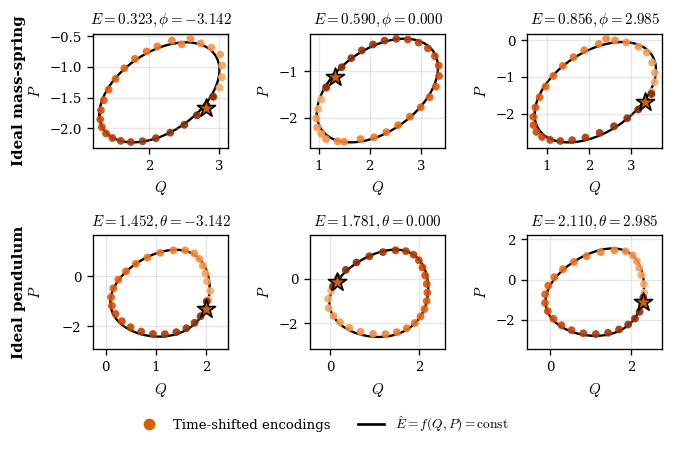

In [19]:
# ============================================================
# Energy recovery time-shift figure: Mass-Spring + Pendulum
# Loads:
#   ./conserved_quantities_results/mass_spring_results.pkl
#   ./conserved_quantities_results/pendulum_results.pkl
#
# Saves:
#   ./manuscript_figures/energy_recovery_time_shift_both_tasks.pdf
#   ./manuscript_figures/energy_recovery_time_shift_both_tasks.png
# ============================================================

import pickle
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D


# ------------------------------------------------------------------
# Styling (same as your mass-spring figure)
# ------------------------------------------------------------------
PALETTE = {
    'HJN':      '#D55E00',
    'Baseline': '#0072B2',
    'Truth':    '#000000',
}

FIG_CONFIG = {
    'text_width_in': 6.9,
    'panel_aspect': 0.80,
    'font_size': 9,
    'tick_size': 8,
    'legend_size': 8,
    'use_tex': False,
    'font_family': 'serif',
}

def apply_style(cfg=FIG_CONFIG):
    mpl.rcParams.update({
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'savefig.dpi': 300,
        'figure.dpi': 120,
        'savefig.bbox': 'tight',
        'font.size': cfg['font_size'],
        'axes.titlesize': cfg['font_size'],
        'axes.labelsize': cfg['font_size'],
        'xtick.labelsize': cfg['tick_size'],
        'ytick.labelsize': cfg['tick_size'],
        'legend.fontsize': cfg['legend_size'],
        'axes.grid': True,
        'grid.alpha': 0.3,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.2,
        'font.family': cfg['font_family'],
        'text.usetex': cfg['use_tex'],
        'mathtext.fontset': 'cm',
    })

def _trunc_cmap(name, lo=0.35, hi=1.0, n=256):
    base = plt.get_cmap(name)
    return mcolors.LinearSegmentedColormap.from_list(
        f"{name}_{lo:.2f}_{hi:.2f}",
        base(np.linspace(lo, hi, n))
    )

PHASE_CMAP = _trunc_cmap('Oranges')

apply_style()


# ------------------------------------------------------------------
# Load pickles
# ------------------------------------------------------------------
with open(
    "./conserved_quantities_results/mass_spring_results.pkl",
    "rb"
) as f:
    ms = pickle.load(f)

with open(
    "./conserved_quantities_results/pendulum_results.pkl",
    "rb"
) as f:
    pend = pickle.load(f)


# ------------------------------------------------------------------
# Unpack mass-spring
# ------------------------------------------------------------------
res_train_ms      = ms["res_train"]
Q_full_ms         = ms["Q_full"]
P_full_ms         = ms["P_full"]
taus_ms           = ms["taus"]
closest_ms        = ms["closest_indices"]
COEFFS            = ms["COEFFS"]

# ------------------------------------------------------------------
# Unpack pendulum
# ------------------------------------------------------------------
res_train_pd      = pend["res_train"]
ts_pd             = pend["ts"]
closest_pd        = pend["closest_indices"]
readouts_pd       = pend["readouts"]

Q_full_pd         = ts_pd["Q_full"]
P_full_pd         = ts_pd["P_full"]
taus_pd           = ts_pd["taus"]

energy_degree_pd  = pend.get("energy_degree", 3)
model_pd          = readouts_pd["energy"][energy_degree_pd]


# ------------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------------
pw = FIG_CONFIG['text_width_in'] / 3.0
ph = pw * FIG_CONFIG['panel_aspect']

fig, axes = plt.subplots(
    2,
    3,
    figsize=(3 * pw, 2 * ph),
    squeeze=False
)

# Row labels anchored to the leftmost axes (axes-fraction coords),
# so they follow the panels through any tight_layout reflow.
for r, label in enumerate(["Ideal mass-spring", "Ideal pendulum"]):
    axes[r, 0].text(
        -0.55, 0.5, label,
        transform=axes[r, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=FIG_CONFIG["font_size"],
        fontweight="bold",
    )


# ============================================================
# FIRST ROW : MASS SPRING
# ============================================================
for ax, idx in zip(axes[0], closest_ms):

    Ec = float(res_train_ms["E"][idx])
    phi = float(res_train_ms["phi"][idx])

    c_const = COEFFS['c_const']
    a       = COEFFS['a']
    b       = COEFFS['b']
    c_quad  = COEFFS['c_quad']
    d       = COEFFS['d']
    e       = COEFFS['e']

    A_q = d**2 - 4 * e * c_quad
    B_q = -2 * b * d + 4 * e * a
    C_q = b**2 - 4 * e * (c_const - Ec)

    disc_q = B_q**2 - 4 * A_q * C_q

    q1 = (-B_q + np.sqrt(disc_q)) / (2 * A_q)
    q2 = (-B_q - np.sqrt(disc_q)) / (2 * A_q)

    qmin, qmax = min(q1, q2), max(q1, q2)

    Q_vals = np.linspace(qmin, qmax, 1000)

    valid_Q = []
    valid_P1 = []
    valid_P2 = []

    for Q in Q_vals:

        A = e
        B = b - d * Q
        C = c_quad * Q**2 - a * Q + c_const - Ec

        disc = max(0, B**2 - 4 * A * C)

        valid_Q.append(Q)
        valid_P1.append((-B + np.sqrt(disc)) / (2 * A))
        valid_P2.append((-B - np.sqrt(disc)) / (2 * A))

    Q_contour = valid_Q + valid_Q[::-1]
    P_contour = valid_P1 + valid_P2[::-1]

    ax.plot(
        Q_contour,
        P_contour,
        color=PALETTE['Truth'],
        lw=1.4,
        zorder=1
    )

    xp = Q_full_ms[:, idx]
    up = P_full_ms[:, idx]

    ax.scatter(
        xp,
        up,
        c=taus_ms,
        cmap=PHASE_CMAP,
        s=22,
        alpha=0.9,
        edgecolors='none',
        zorder=3
    )

    ax.scatter(
        xp[0],
        up[0],
        color=PALETTE['HJN'],
        marker='*',
        s=130,
        edgecolors='black',
        linewidths=1.0,
        zorder=5
    )

    ax.set_title(
        rf"$E={Ec:.3f},\phi={phi:.3f}$",
        fontweight='bold'
    )

    ax.set_xlabel(r"$Q$")
    ax.set_ylabel(r"$P$")


# ============================================================
# SECOND ROW : PENDULUM
# ============================================================
for ax, idx in zip(axes[1], closest_pd):

    Ec = float(res_train_pd["E"][idx])
    theta = float(res_train_pd["phi"][idx])

    xp = Q_full_pd[:, idx]
    up = P_full_pd[:, idx]

    qmin, qmax = xp.min(), xp.max()
    pmin, pmax = up.min(), up.max()

    dq = (qmax - qmin) or 1.0
    dp = (pmax - pmin) or 1.0

    qs = np.linspace(qmin - 0.18*dq, qmax + 0.18*dq, 300)
    ps = np.linspace(pmin - 0.18*dp, pmax + 0.18*dp, 300)

    QQ, PP = np.meshgrid(qs, ps)

    EE = model_pd.predict(
        np.column_stack([QQ.ravel(), PP.ravel()])
    ).reshape(QQ.shape)

    ax.contour(
        QQ,
        PP,
        EE,
        levels=[Ec],
        colors='k',
        linewidths=1.4,
        zorder=1
    )

    ax.scatter(
        xp,
        up,
        c=taus_pd,
        cmap=PHASE_CMAP,
        s=22,
        alpha=0.9,
        edgecolors='none',
        zorder=3
    )

    ax.scatter(
        xp[0],
        up[0],
        color=PALETTE['HJN'],
        marker='*',
        s=130,
        edgecolors='black',
        linewidths=1.0,
        zorder=5
    )

    ax.set_title(
        rf"$E={Ec:.3f},\theta={theta:.3f}$",
        fontweight='bold'
    )

    ax.set_xlabel(r"$Q$")
    ax.set_ylabel(r"$P$")


# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        color=PALETTE['HJN'],
        marker='o',
        lw=0,
        label='Time-shifted encodings'
    ),
    Line2D(
        [0], [0],
        color=PALETTE['Truth'],
        lw=1.6,
        label=r'$\hat{E}=f(Q,P)=\mathrm{const}$'
    ),
]

fig.legend(
    handles=handles,
    loc='lower center',
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.57, -0.02)
)

fig.align_ylabels()

fig.tight_layout(rect=(0.14, 0.05, 1, 1))


# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------
FIG_DIR = Path("./manuscript_figures")
FIG_DIR.mkdir(exist_ok=True)

fname = FIG_DIR / "energy_recovery_time_shift_both_tasks.pdf"

fig.savefig(fname)
fig.savefig(fname.with_suffix(".png"))

print(f"saved: {fname}")

plt.show()

In [16]:
# ======================================================================
# EXPERIMENT 4 — frame sweep / HSIC detector: config
# ======================================================================
import pandas as pd

# Colours for the sweep arms. Okabe-Ito, deliberately NOT reusing the
# method colours from PALETTE (there are no competing methods here).
ARM_COLORS  = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
ARM_MARKERS = ['o', 's', '^', 'v', 'D', 'P']

# The sweep pickle was saved with a relative path; resolve it here.
FRAME_CANDIDATES = [
    HJN_ROOT / "frame_sweep_res.pkl",
    HJN_ROOT / "frame_sweep_outputs" / "frame_sweep_res.pkl",
    Path.cwd() / "frame_sweep_res.pkl",
]

def _resolve_frame_path(candidates=FRAME_CANDIDATES):
    for p in candidates:
        if p.exists():
            print(f"frame sweep pickle: {p}")
            return p
    raise FileNotFoundError(
        "frame_sweep_res.pkl not found. Tried:\n  "
        + "\n  ".join(str(p) for p in candidates)
        + "\nRun this in a terminal to locate it:\n"
          "  find ~/Desktop -name 'frame_sweep_res.pkl' 2>/dev/null")

FRAME_PATH = _resolve_frame_path()

frame sweep pickle: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/frame_sweep_res.pkl


In [17]:
# ======================================================================
# EXPERIMENT 4 — load
# ======================================================================
# The pickle holds float32/float64 prediction tensors as well as the
# results table. Only 'df' and 'checks' are used downstream, but pickle
# rebuilds every object it stored, so `torch` must be importable here.
try:
    with open(FRAME_PATH, "rb") as f:
        FRAME = pickle.load(f)
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        f"{e}\n\nThe sweep pickle contains torch tensors (preds32/preds64), so "
        f"unpickling needs torch in this kernel. Either install it here, or "
        f"re-save a slim pickle from the sweep notebook:\n"
        f"    slim = {{'df': res['df'], 'checks': res['checks']}}\n"
        f"    pickle.dump(slim, open('frame_sweep_slim.pkl','wb'))\n"
        f"and point FRAME_CANDIDATES at that file instead.") from e

_fd = FRAME['df']
print(f"Loaded frame sweep: {len(_fd)} sweep points, "
      f"arms={list(dict.fromkeys(_fd['arm_label']))}")
print(f"  columns present: r64={'r64' in _fd.columns}  "
      f"e_num_mean={'e_num_mean' in _fd.columns}")
print(f"  checks: symplecticity_pass={FRAME['checks'].get('sigma_pairing_pass')}  "
      f"max|r64-1|={FRAME['checks'].get('r64_max_dev', float('nan')):.3e}")

Loaded frame sweep: 46 sweep points, arms=['squeeze', 'shear', 'rotate $a_0$=100', 'rotate $a_0$=1000', 'rotate $a_0$=10000']
  columns present: r64=True  e_num_mean=True
  checks: symplecticity_pass=True  max|r64-1|=3.462e-08


In [18]:
def detector_summary(res, r32_tol=0.01, skeel_mult=10.0, enum_mult=2.0,
                     verbose=True):
    """
    Thresholds are set from the identity frame S = I and never from HSIC,
    so the detector claim is not circular.
    """
    df = res['df']
    ch = res['checks']
    floor = enum_mult * ch['e_num_identity']
    skeel_thr = skeel_mult * ch['skeel_identity']
    fires = df['hsic'] > 1e-9
    links = {
        'L1 conditioning': df['skeel_med'] > skeel_thr,
        'L2 float amplification': df['e_num_mean'] > floor,
        'L3 practical impact': (df['r32'] - 1.0).abs() > r32_tol,
    }
    if verbose:
        print(f"thresholds from S=I: Skeel > {skeel_thr:.3g}, "
              f"e_num > {floor:.3g}, |r32-1| > {r32_tol:g}\n")
    out = {}
    for name, harmful in links.items():
        fn = int((~fires & harmful).sum())
        out[name] = dict(n_harmful=int(harmful.sum()), false_negatives=fn,
                         fires_early=int((fires & ~harmful).sum()))
        if verbose:
            print(f"{name:24s}  harmful {harmful.sum():2d}/{len(df)}  "
                  f"missed by HSIC: {fn}  (fires before onset: "
                  f"{out[name]['fires_early']})")
    silent = df[~fires]
    out['n_silent'] = int(len(silent))
    out['silent_max_enum'] = float(silent['e_num_mean'].max())
    out['silent_max_r32_dev'] = float((silent['r32'] - 1.0).abs().max())
    out['silent_kappa_range'] = (float(silent['kappa_med'].min()),
                                 float(silent['kappa_med'].max()))
    out['firing_hsic_range'] = (float(df.loc[fires, 'hsic'].min()),
                                float(df.loc[fires, 'hsic'].max()))
    if verbose:
        print(f"\nHSIC exactly 0 on {out['n_silent']}/{len(df)} frames.")
        print(f"  those span kappa [{out['silent_kappa_range'][0]:.2e}, "
              f"{out['silent_kappa_range'][1]:.2e}]")
        print(f"  max e_num among them   : {out['silent_max_enum']:.3e}")
        print(f"  max |r32 - 1| among them: {out['silent_max_r32_dev']:.3e}")
        print(f"HSIC when firing: [{out['firing_hsic_range'][0]:.4f}, "
              f"{out['firing_hsic_range'][1]:.4f}]")


    # kappa as null control: it is neither necessary nor sufficient
    sq = df[df['kind'] == 'squeeze']
    out['kappa_null'] = dict(
        squeeze_kappa_range=(float(sq['kappa_med'].min()), float(sq['kappa_med'].max())),
        squeeze_skeel_range=(float(sq['skeel_med'].min()), float(sq['skeel_med'].max())),
        squeeze_max_hsic=float(sq['hsic'].max()),
        squeeze_max_r32_dev=float((sq['r32'] - 1.0).abs().max()),
    )
    for arm in df.loc[df['kind'] == 'rotate', 'arm'].unique():
        s = df[df['arm'] == arm]
        out['kappa_null'][f'{arm}_r32_range'] = (float(s['r32'].min()),
                                                 float(s['r32'].max()))
    if verbose:
        kn = out['kappa_null']
        print(f"\nkappa null control:")
        print(f"  squeeze: kappa {kn['squeeze_kappa_range'][0]:.2e} -> "
              f"{kn['squeeze_kappa_range'][1]:.2e} ({np.log10(kn['squeeze_kappa_range'][1]/kn['squeeze_kappa_range'][0]):.0f} decades), "
              f"Skeel constant at {kn['squeeze_skeel_range'][0]:.6f}")
        print(f"  squeeze: max HSIC {kn['squeeze_max_hsic']:.3e}, "
              f"max |r32-1| {kn['squeeze_max_r32_dev']:.3e}")
        for arm in df.loc[df['kind'] == 'rotate', 'arm'].unique():
            lo, hi = kn[f'{arm}_r32_range']
            print(f"  {arm}: kappa pinned, r32 in [{lo:.3f}, {hi:.3f}]")
    return out


def paper_table(res, latex=True):
    """Benign block then harmful block, theta in degrees."""
    df = res['df'].set_index('key')
    benign = ['squeeze|1', 'squeeze|100000', 'rotate10000|0', 'rotate10000|90deg']
    harmful = ['rotate10000|1e-06', 'rotate10000|0.0001',
               'rotate10000|0.01', 'rotate10000|0.1']
    cols = ['arm_label', 'param_label', 'kappa_med', 'skeel_med',
            'hsic', 'e_num_mean', 'r32']
    t = df.loc[benign + harmful, cols]
    if latex:
        for block, keys in (("benign", benign), ("harmful", harmful)):
            print(f"% --- {block} ---")
            for k in keys:
                r = df.loc[k]
                print(f"{r['arm_label']} & {r['param_label']} & {r['kappa_med']:.3e} & "
                      f"{r['skeel_med']:.2e} & {r['hsic']:.4f} & "
                      f"{r['e_num_mean']:.2e} & {r['r32']:.3f} \\\\")
    return t


def report_table(res, keys=None, latex=True):
    """
    THE table reported in the paper.

    kappa appears here and nowhere in the figure: its role is a control, not a
    metric.  Rows 1-2 hold kappa's ten-decade march at zero damage; rows 3-7
    hold kappa pinned to every printed digit while the damage spans seven
    decades; row 8 is the theta = 90 deg return-to-baseline.
    """
    df = res['df'].set_index('key')
    if keys is None:
        keys = ['squeeze|1', 'squeeze|100000',
                'rotate10000|0', 'rotate10000|1e-06', 'rotate10000|0.0001',
                'rotate10000|0.01', 'rotate10000|0.1', 'rotate10000|90deg']

    cols = ['arm_label', 'param_label', 'kappa_med', 'skeel_med',
            'hsic', 'e_num_mean', 'r32']
    if 'r64' in df.columns:
        cols.append('r64')
    t = df.loc[keys, cols]

    hdr = "  REPORTED TABLE  (paper)  "
    print("=" * 100)
    print(hdr.center(100, "="))
    print("=" * 100)
    fmt = {'kappa_med': '{:.6e}'.format, 'skeel_med': '{:.3e}'.format,
           'hsic': '{:.4f}'.format, 'e_num_mean': '{:.2e}'.format,
           'r32': '{:.4f}'.format}
    if 'r64' in t.columns:
        fmt['r64'] = '{:.8f}'.format
    print(t.to_string(index=False, formatters=fmt))
    print("-" * 100)

    if latex:
        print("% ---- LaTeX rows ----")
        for _, r in t.iterrows():
            line = (f"{r['arm_label']} & {r['param_label']} & "
                    f"{r['kappa_med']:.3e} & {r['skeel_med']:.3e} & "
                    f"{r['hsic']:.4f} & {r['e_num_mean']:.2e} & {r['r32']:.3f}")
            if 'r64' in t.columns:
                line += f" & {r['r64']:.6f}"
            print(line + r" \\")
        print("=" * 100)
    return t

In [19]:
# ======================================================================
# EXPERIMENT 4 — figure (notebook house style)
# ======================================================================
def plot_frame_sweep_grid(res=None, *, floors=None, ylim=None,
                          marker_size=34, save=True, fname=None):
    """
    Three panels, shared y = L_HSIC, one per link of the chain.
      (a) x = Skeel      map conditioning
      (b) x = e_num      float32 amplification
      (c) x = |r32 - 1|  practical impact
    No vertical threshold lines. Baseline frames have |r32 - 1| identically 0
    and are clipped to the left edge of panel (c).
    Sized to FIG_CONFIG['text_width_in'] so it matches the other figures.
    """
    res = FRAME if res is None else res
    cfg = FIG_CONFIG
    pw  = cfg['text_width_in'] / 3.0
    ph  = pw * cfg['panel_aspect'] * 1.55

    df = res['df'].copy()
    df['r32_dev'] = (df['r32'] - 1.0).abs()
    floors = {'r32_dev': 1e-7} if floors is None else floors

    specs = [
        ('skeel_med',  'Skeel condition number', '(a) Map conditioning'),
        ('e_num_mean', r'$e_{\mathrm{num}}$',    '(b) Float32 amplification'),
        ('r32_dev',    r'$|r_{32}-1|$',          '(c) Practical impact'),
    ]

    arms = list(dict.fromkeys(df['arm_label']))
    col = {a: ARM_COLORS[i % len(ARM_COLORS)]  for i, a in enumerate(arms)}
    mk  = {a: ARM_MARKERS[i % len(ARM_MARKERS)] for i, a in enumerate(arms)}

    fig, ax = plt.subplots(1, 3, figsize=(3 * pw, ph), sharey=True)

    silent = df['hsic'] <= 0.0          # HSIC is exactly 0 or clearly nonzero

    for a, (xk, xlab, title) in zip(ax, specs):
        x = df[xk].clip(lower=floors[xk]) if xk in floors else df[xk]
        for arm in arms:
            m = df['arm_label'] == arm
            # firing: filled. silent: hollow, so the HSIC=0 pile-up stays countable.
            a.scatter(x[m & ~silent], df.loc[m & ~silent, 'hsic'], s=marker_size,
                      color=col[arm], marker=mk[arm], label=arm,
                      edgecolor='k', linewidth=0.3, zorder=3)
            a.scatter(x[m & silent], df.loc[m & silent, 'hsic'], s=marker_size,
                      facecolor='none', marker=mk[arm],
                      edgecolor=col[arm], linewidth=0.9, zorder=4)
        a.set_xscale('log')
        a.xaxis.set_major_locator(mpl.ticker.LogLocator(numticks=5))
        a.xaxis.set_minor_locator(mpl.ticker.NullLocator())
        a.set_xlabel(xlab)
        a.set_title(title, fontweight='bold', pad=6)
        a.axhline(0, color='0.4', lw=0.9, zorder=1)
        a.grid(alpha=0.22, which='both')

    ax[0].set_ylabel(r'$\mathcal{L}_{\mathrm{HSIC}}$')
    # HSIC is bimodal: exactly 0 (15 frames) or ~1e-3 to 1e-1 (31 frames).
    # symlog keeps the zeros on a visible baseline instead of merging them
    # with the smallest firing value.
    ax[0].set_yscale('symlog', linthresh=1e-3, linscale=0.4)
    if ylim is None:
        ylim = (-2e-4, 2.0 * float(df['hsic'].max()))
    ax[0].set_ylim(*ylim)
    ax[0].yaxis.set_minor_locator(mpl.ticker.NullLocator())

    handles = [Line2D([0], [0], color=col[a], marker=mk[a], ms=4.5, lw=0,
                      markeredgecolor='k', markeredgewidth=0.3, label=a)
               for a in arms]
    handles += [Line2D([0], [0], color='0.3', marker='o', ms=4.5, lw=0,
                       markerfacecolor='none', markeredgewidth=0.9,
                       label=r'$\mathcal{L}_{\mathrm{HSIC}}=0$')]
    fig.legend(handles=handles, loc='upper center', ncol=min(len(handles), 6),
               frameon=False, bbox_to_anchor=(0.5, 1.005),
               fontsize=cfg['legend_size'] - 1.5,
               columnspacing=0.9, handletextpad=0.3, borderaxespad=0.0)

    fig.tight_layout(rect=(0, 0, 1, 0.945))

    if save:
        if fname is None:
            fname = FIG_DIR / "exp4_frame_sweep.pdf"
        fig.savefig(fname)
        fig.savefig(Path(fname).with_suffix('.png'))
        print(f"saved: {fname}")
    return fig, ax

         arm_label           param_label    kappa_med    skeel_med         hsic   e_num_mean          r32
           squeeze                 $a$=1 2.781498e+01 5.674487e+00 0.000000e+00 1.275120e-06 1.000000e+00
           squeeze                $a$=10 2.774188e+03 5.674487e+00 0.000000e+00 1.258558e-06 9.999999e-01
           squeeze               $a$=100 2.774187e+05 5.674487e+00 0.000000e+00 1.277549e-06 9.999996e-01
           squeeze              $a$=1000 2.774187e+07 5.674487e+00 0.000000e+00 1.304562e-06 9.999996e-01
           squeeze             $a$=10000 2.774187e+09 5.674487e+00 0.000000e+00 1.356788e-06 1.000000e+00
           squeeze            $a$=100000 2.774187e+11 5.674487e+00 0.000000e+00 1.264892e-06 9.999999e-01
             shear     $\tilde\lambda$=0 2.781498e+01 5.674487e+00 0.000000e+00 1.275120e-06 1.000000e+00
             shear   $\tilde\lambda$=0.1 2.800270e+01 5.773167e+00 0.000000e+00 1.270901e-06 1.000000e+00
             shear     $\tilde\lambda$=1 2.728

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved: /home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN/manuscript_figures/exp4_frame_sweep.pdf


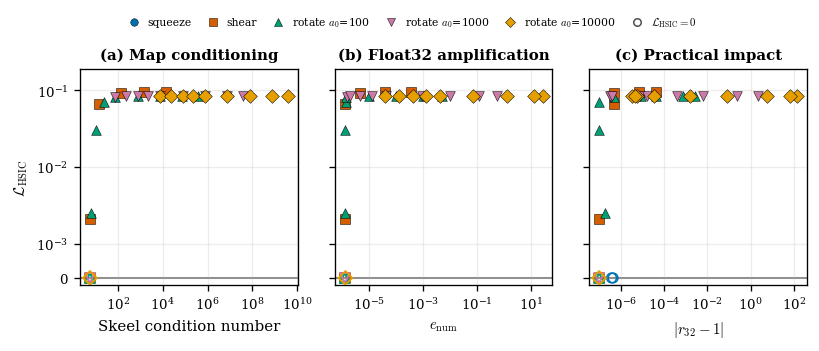

In [20]:
# ======================================================================
# EXPERIMENT 4 — numbers + figure
# ======================================================================
with pd.option_context('display.float_format', lambda v: f'{v:.6e}'):
    print(FRAME['df'][['arm_label', 'param_label', 'kappa_med', 'skeel_med',
                       'hsic', 'e_num_mean', 'r32']].to_string(index=False))

print(); stats = detector_summary(FRAME)
print(); tab   = report_table(FRAME)

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='.*timestamp seems very low.*')
    fig4, _ = plot_frame_sweep_grid(FRAME)
plt.show()


NO HSIC ABLATION

In [9]:
# ======================================================================
# no-HSIC ABLATION — configuration & loading   (READ-ONLY, saves nothing)
# Requires notebook cells 1, 2, 4 (imports/config, ACC_SUB, normalized_loss_matrix).
# ======================================================================

# ----------------------- user switches --------------------------------
INCLUDE_ORIGINAL = False   # True -> add a column with the original (full) HJN results
BOOT_SEED        = 42     # BCa bootstrap seed (None -> unseeded, like Table 1)
# ----------------------------------------------------------------------

ABL_ROOT = HJN_ROOT / "no_HSIC_ablation_results"
ABL_SUB  = "prediction_results_all_trajectories_no_HSIC"

# Same row layout as Table 1.  A = temporal (multiple_periods), B = energy (high_energy)
ABL_ROWS = [('T1-A', 1, 'multiple_periods'), ('T1-B', 1, 'high_energy'),
            ('T2-A', 2, 'multiple_periods'), ('T2-B', 2, 'high_energy'),
            ('T4-A', 4, 'multiple_periods'), ('T4-B', 4, 'high_energy')]

def _abl_load(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    with open(path, "rb") as f:          # read-only
        return pickle.load(f)

ABL_ACC, ORIG_HJN_ACC = {}, {}
for _, t, ds in ABL_ROWS:
    name = f"task_{t}_results_{ds}.pkl"
    ABL_ACC.setdefault(ds, {})[t]      = _abl_load(ABL_ROOT / ABL_SUB / name)
    ORIG_HJN_ACC.setdefault(ds, {})[t] = _abl_load(HJN_ROOT / ACC_SUB / name)

print("Loaded no-HSIC ablation + original HJN accuracy pickles:")
for _, t, ds in ABL_ROWS:
    a, o = ABL_ACC[ds][t], ORIG_HJN_ACC[ds][t]
    print(f"  [{ds:16s} | task{t}]  no-HSIC N_traj={a['N_traj']:3d} N_obs={a['N_obs']:3d}   "
          f"original N_traj={o['N_traj']:3d} N_obs={o['N_obs']:3d}")

Loaded no-HSIC ablation + original HJN accuracy pickles:
  [multiple_periods | task1]  no-HSIC N_traj= 24 N_obs= 97   original N_traj= 24 N_obs= 97
  [high_energy      | task1]  no-HSIC N_traj= 25 N_obs= 32   original N_traj= 25 N_obs= 32
  [multiple_periods | task2]  no-HSIC N_traj= 20 N_obs=144   original N_traj= 20 N_obs=144
  [high_energy      | task2]  no-HSIC N_traj= 13 N_obs= 37   original N_traj= 13 N_obs= 37
  [multiple_periods | task4]  no-HSIC N_traj= 16 N_obs=334   original N_traj= 16 N_obs=334
  [high_energy      | task4]  no-HSIC N_traj= 16 N_obs=115   original N_traj= 16 N_obs=115


In [10]:
def _bca_mean_ci_seeded(values, seed, conf=CONF_LEVEL, n_boot=N_BOOT):
    """Same as _bca_mean_ci, but with a fresh RNG from `seed` on every call,
    so each row's CI is reproducible regardless of evaluation order."""
    kw = dict(n_resamples=n_boot, confidence_level=conf, method='BCa')
    try:
        try:   # SciPy >= 1.15
            r = scipy_bootstrap((values,), np.mean, rng=np.random.default_rng(seed), **kw)
        except TypeError:   # older SciPy
            r = scipy_bootstrap((values,), np.mean, random_state=np.random.default_rng(seed), **kw)
        return float(r.confidence_interval.low), float(r.confidence_interval.high)
    except Exception as e:
        warnings.warn(f"BCa CI failed ({e}); returning NaNs.")
        return float('nan'), float('nan')

def ablation_accuracy_stats(results, seed):
    """Identical metric to accuracy_stats (L2/sqrtE, median over obs per trajectory,
    mean + BCa CI across trajectories), with a seeded bootstrap."""
    L = normalized_loss_matrix(results)                 # same function as Table 1
    ptm = np.median(L, axis=0)                          # (N_traj,)
    lo, hi = _bca_mean_ci_seeded(ptm, seed)
    return {
        'mean':   float(np.mean(ptm)),
        'std':    float(np.std(ptm, ddof=1)),
        'median': float(np.median(ptm)),
        'q1':     float(np.percentile(ptm, 25)),
        'q3':     float(np.percentile(ptm, 75)),
        'ci_lo': lo, 'ci_hi': hi,
        'N_traj': results['N_traj'], 'N_obs': results['N_obs'],
    }

def _same_trajectories(a, b):
    if a['N_traj'] != b['N_traj'] or a['N_obs'] != b['N_obs']:
        return False
    return (np.array_equal(np.asarray(a['trajectory_ids']), np.asarray(b['trajectory_ids']))
            and np.allclose(np.asarray(a['energies'], float), np.asarray(b['energies'], float),
                            rtol=1e-10, atol=0))

In [11]:
def print_ablation_numbers(abl, orig, *, include_original, seed):
    cols = ["no-HSIC"] + (["original HJN"] if include_original else [])
    print("=" * 78)
    print("no-HSIC ABLATION — L2/sqrtE  (mean of per-trajectory medians, BCa CI)")
    print("=" * 78)
    print(f"conf={CONF_LEVEL}  n_boot={N_BOOT}  seed={seed}")
    print(f"LaTeX column order: {' | '.join(cols)}\n")

    latex_rows = []
    for label, t, ds in ABL_ROWS:
        a = ablation_accuracy_stats(abl[ds][t], seed)
        print(f"----- {label}  (task {t}, {ds}) | N_traj={a['N_traj']} N_obs={a['N_obs']} -----")
        entries = [('noHSIC', a)]
        if include_original:
            o_res = orig[ds][t]
            if not _same_trajectories(abl[ds][t], o_res):
                print("  !! WARNING: ablation and original are not on identical trajectories")
            entries.append(('orig', ablation_accuracy_stats(o_res, seed)))
        for tag, s in entries:
            print(f"  L2/sqrtE {tag:6s}: mean={s['mean']:.4f}  CI=[{s['ci_lo']:.4f}, {s['ci_hi']:.4f}]  "
                  f"median={s['median']:.4f}  IQR=[{s['q1']:.4f}, {s['q3']:.4f}]  std={s['std']:.4f}")
        print()
        latex_rows.append(
            f"{label}\n"
            + "".join(f"& {s['mean']:.3f} [{s['ci_lo']:.3f}, {s['ci_hi']:.3f}]\n" for _, s in entries)
            + "\\\\"
        )

    print("=" * 78)
    print("PASTE-READY LaTeX ROWS")
    print("=" * 78)
    print("\n\n".join(latex_rows))

print_ablation_numbers(ABL_ACC, ORIG_HJN_ACC,
                       include_original=INCLUDE_ORIGINAL, seed=BOOT_SEED)

no-HSIC ABLATION — L2/sqrtE  (mean of per-trajectory medians, BCa CI)
conf=0.95  n_boot=10000  seed=42
LaTeX column order: no-HSIC

----- T1-A  (task 1, multiple_periods) | N_traj=24 N_obs=97 -----
  L2/sqrtE noHSIC: mean=0.0761  CI=[0.0726, 0.0801]  median=0.0730  IQR=[0.0687, 0.0825]  std=0.0095

----- T1-B  (task 1, high_energy) | N_traj=25 N_obs=32 -----
  L2/sqrtE noHSIC: mean=0.0615  CI=[0.0511, 0.0743]  median=0.0546  IQR=[0.0383, 0.0823]  std=0.0299

----- T2-A  (task 2, multiple_periods) | N_traj=20 N_obs=144 -----
  L2/sqrtE noHSIC: mean=0.1602  CI=[0.1346, 0.1914]  median=0.1467  IQR=[0.1037, 0.1987]  std=0.0652

----- T2-B  (task 2, high_energy) | N_traj=13 N_obs=37 -----
  L2/sqrtE noHSIC: mean=0.3068  CI=[0.2457, 0.3779]  median=0.2942  IQR=[0.2200, 0.4063]  std=0.1265

----- T4-A  (task 4, multiple_periods) | N_traj=16 N_obs=334 -----
  L2/sqrtE noHSIC: mean=0.5258  CI=[0.4079, 0.6704]  median=0.4370  IQR=[0.2885, 0.8346]  std=0.2775

----- T4-B  (task 4, high_energy) | 

In [15]:
# ======================================================================
# no-HSIC ABLATION — Exp 3 (within-segment consistency): config & loading
# READ-ONLY: nothing is written to disk.
# Requires only notebook cell 1 (imports, HJN_ROOT).
# ======================================================================

# ----------------------- user switch ----------------------------------
ABL3_INCLUDE_ORIGINAL = False   # True -> add a column with the original (full) HJN results
# ----------------------------------------------------------------------

ABL3_DIR  = HJN_ROOT / "no_HSIC_ablation_results" / "variance_results_no_HSIC"
ORIG3_DIR = HJN_ROOT / "variance_results"          # same folder as VAR_SUB in the Exp-3 cells
ABL3_ROWS = [(1, 'multiple_periods'), (2, 'multiple_periods'), (4, 'multiple_periods')]

_ABL3_REQ = ['variance_avg', 'final_median', 'final_q1', 'final_q3',
             'final_ci_lower', 'final_ci_upper', 'ci_method',
             'N_traj', 'N_obs', 't', 'Tmax', 'segment_indices_dict']

def _abl3_load(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    with open(path, "rb") as f:          # read-only
        r = pickle.load(f)
    missing = [k for k in _ABL3_REQ if k not in r]
    if missing:
        raise KeyError(f"{path.name}: missing keys {missing}")
    return r

ABL3_VAR, ORIG3_VAR = {}, {}
for t, ds in ABL3_ROWS:
    name = f"task_{t}_variance_results_{ds}.pkl"
    ABL3_VAR[(t, ds)]  = _abl3_load(ABL3_DIR  / name)
    ORIG3_VAR[(t, ds)] = _abl3_load(ORIG3_DIR / name)

print("Loaded Exp-3 variance pickles (no-HSIC + original HJN):")
for t, ds in ABL3_ROWS:
    a, o = ABL3_VAR[(t, ds)], ORIG3_VAR[(t, ds)]
    print(f"  [task{t} | {ds}]  no-HSIC N_traj={a['N_traj']:3d} N_obs={a['N_obs']:3d} n={a.get('n', 1)}   "
          f"original N_traj={o['N_traj']:3d} N_obs={o['N_obs']:3d} n={o.get('n', 1)}")

Loaded Exp-3 variance pickles (no-HSIC + original HJN):
  [task1 | multiple_periods]  no-HSIC N_traj= 24 N_obs= 97 n=1   original N_traj= 24 N_obs= 97 n=1
  [task2 | multiple_periods]  no-HSIC N_traj= 20 N_obs=144 n=1   original N_traj= 20 N_obs=144 n=1
  [task4 | multiple_periods]  no-HSIC N_traj= 16 N_obs=334 n=2   original N_traj= 16 N_obs=334 n=2


In [16]:
def _abl3_same_structure(a, o):
    """Same test grid, Tmax and segmentation (trajectory ids are not stored in these pickles)."""
    if a['N_traj'] != o['N_traj'] or a['N_obs'] != o['N_obs']:
        return False
    ta, to = np.asarray(a['t'], float), np.asarray(o['t'], float)
    seg = lambda r: {int(k): [int(i) for i in v] for k, v in r['segment_indices_dict'].items()}
    return (bool(np.isclose(float(a['Tmax']), float(o['Tmax'])))
            and ta.shape == to.shape and np.allclose(ta, to, rtol=1e-6, atol=1e-8)
            and seg(a) == seg(o))

def print_exp3_ablation_numbers(abl, orig, *, include_original):
    cols = ["no-HSIC"] + (["original HJN"] if include_original else [])
    print("=" * 78)
    print("no-HSIC ABLATION — EXPERIMENT 3: within-segment consistency at FULL observation")
    print("Metric: per-segment mean CV of learned coordinates, median[IQR] over trajectories")
    print("(stored values, as in the original Exp-3 table; CI is BCa unless fallback noted)")
    print("=" * 78)
    print(f"LaTeX column order: Task | {' | '.join(cols)}\n")

    rows = []
    for t, ds in ABL3_ROWS:
        a = abl[(t, ds)]
        entries = [('noHSIC', a)]
        if include_original:
            o = orig[(t, ds)]
            if not _abl3_same_structure(a, o):
                print(f"  !! WARNING task{t}: no-HSIC and original runs are not structurally identical")
            entries.append(('orig', o))

        print(f"----- T{t}  ({ds}) | N_traj={a['N_traj']} N_obs={a['N_obs']} -----")
        for tag, r in entries:
            print(f"  T{t}  {tag:6s}: median={r['final_median']:.4f}  "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]  "
                  f"CI({r['ci_method']})=[{r['final_ci_lower']:.4f}, {r['final_ci_upper']:.4f}]")
        print()

        rows.append(
            f"T{t}\n"
            + "".join(f"& {r['final_median']:.4f} [{r['final_q1']:.4f}, {r['final_q3']:.4f}]\n"
                      for _, r in entries)
            + "\\\\"
        )

    print("=" * 78)
    print(f"PASTE-READY LaTeX ROWS (Task | {' | '.join(cols)})")
    print("=" * 78)
    print("\n\n".join(rows))

print_exp3_ablation_numbers(ABL3_VAR, ORIG3_VAR, include_original=ABL3_INCLUDE_ORIGINAL)

no-HSIC ABLATION — EXPERIMENT 3: within-segment consistency at FULL observation
Metric: per-segment mean CV of learned coordinates, median[IQR] over trajectories
(stored values, as in the original Exp-3 table; CI is BCa unless fallback noted)
LaTeX column order: Task | no-HSIC

----- T1  (multiple_periods) | N_traj=24 N_obs=97 -----
  T1  noHSIC: median=0.0262  IQR=[0.0121, 0.1452]  CI(BCa)=[0.0123, 0.0885]

----- T2  (multiple_periods) | N_traj=20 N_obs=144 -----
  T2  noHSIC: median=0.0927  IQR=[0.0317, 0.3559]  CI(BCa)=[0.0319, 0.3369]

----- T4  (multiple_periods) | N_traj=16 N_obs=334 -----
  T4  noHSIC: median=0.0529  IQR=[0.0306, 0.0929]  CI(BCa)=[0.0319, 0.0915]

PASTE-READY LaTeX ROWS (Task | no-HSIC)
T1
& 0.0262 [0.0121, 0.1452]
\\

T2
& 0.0927 [0.0317, 0.3559]
\\

T4
& 0.0529 [0.0306, 0.0929]
\\


HIGH ENERGY

In [5]:
# ======================================================================
# no-HSIC ABLATION — Exp 3, Test B (high_energy): config & loading
# READ-ONLY: nothing is written to disk.
# Requires only notebook cell 1 (imports, HJN_ROOT).
# ======================================================================

# ----------------------- user switch ----------------------------------
ABL3B_INCLUDE_ORIGINAL = False   # True -> add a column with the original (full) HJN results
# ----------------------------------------------------------------------

ABL3B_DIR  = HJN_ROOT / "no_HSIC_ablation_results" / "variance_results_no_HSIC"
ORIG3B_DIR = HJN_ROOT / "variance_results"          # same folder as VAR_SUB in the Exp-3 cells
ABL3B_ROWS = [(1, 'high_energy'), (2, 'high_energy'), (4, 'high_energy')]

_ABL3B_REQ = ['variance_avg', 'final_median', 'final_q1', 'final_q3',
              'final_ci_lower', 'final_ci_upper', 'ci_method',
              'N_traj', 'N_obs', 't', 'Tmax', 'segment_indices_dict']

def _abl3b_load(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}")
    with open(path, "rb") as f:          # read-only
        r = pickle.load(f)
    missing = [k for k in _ABL3B_REQ if k not in r]
    if missing:
        raise KeyError(f"{path.name}: missing keys {missing}")
    return r

def _load_abl3b():
    abl, orig = {}, {}
    for t, ds in ABL3B_ROWS:
        name = f"task_{t}_variance_results_{ds}.pkl"
        abl[(t, ds)]  = _abl3b_load(ABL3B_DIR  / name)
        orig[(t, ds)] = _abl3b_load(ORIG3B_DIR / name)
    return abl, orig

ABL3B_VAR, ORIG3B_VAR = _load_abl3b()

def _report_abl3b():
    print("Loaded Exp-3 Test-B variance pickles (no-HSIC + original HJN):")
    for t, ds in ABL3B_ROWS:
        a, o = ABL3B_VAR[(t, ds)], ORIG3B_VAR[(t, ds)]
        print(f"  [task{t} | {ds}]  no-HSIC N_traj={a['N_traj']:3d} N_obs={a['N_obs']:3d} n={a.get('n', 1)}   "
              f"original N_traj={o['N_traj']:3d} N_obs={o['N_obs']:3d} n={o.get('n', 1)}")

_report_abl3b()

Loaded Exp-3 Test-B variance pickles (no-HSIC + original HJN):
  [task1 | high_energy]  no-HSIC N_traj= 25 N_obs= 32 n=1   original N_traj= 25 N_obs= 32 n=1
  [task2 | high_energy]  no-HSIC N_traj= 13 N_obs= 37 n=1   original N_traj= 13 N_obs= 37 n=1
  [task4 | high_energy]  no-HSIC N_traj= 16 N_obs=115 n=2   original N_traj= 16 N_obs=115 n=2


In [6]:
def _abl3b_same_structure(a, o):
    """Same test grid, Tmax and segmentation (trajectory ids are not stored in these pickles)."""
    if a['N_traj'] != o['N_traj'] or a['N_obs'] != o['N_obs']:
        return False
    ta, to = np.asarray(a['t'], float), np.asarray(o['t'], float)
    seg = lambda r: {int(k): [int(i) for i in v] for k, v in r['segment_indices_dict'].items()}
    return (bool(np.isclose(float(a['Tmax']), float(o['Tmax'])))
            and ta.shape == to.shape and np.allclose(ta, to, rtol=1e-6, atol=1e-8)
            and seg(a) == seg(o))

def print_exp3b_ablation_numbers(abl, orig, *, include_original):
    cols = ["no-HSIC"] + (["original HJN"] if include_original else [])
    print("=" * 78)
    print("no-HSIC ABLATION — EXPERIMENT 3, TEST B: within-segment consistency at FULL observation")
    print("Metric: per-segment mean CV of learned coordinates, median[IQR] over trajectories")
    print("(stored values, as in the original Exp-3 table; CI is BCa unless fallback noted)")
    print("=" * 78)
    print(f"LaTeX column order: Task | {' | '.join(cols)}\n")

    rows = []
    for t, ds in ABL3B_ROWS:
        a = abl[(t, ds)]
        entries = [('noHSIC', a)]
        if include_original:
            o = orig[(t, ds)]
            if not _abl3b_same_structure(a, o):
                print(f"  !! WARNING task{t}: no-HSIC and original runs are not structurally identical")
            entries.append(('orig', o))

        print(f"----- T{t}-B  ({ds}) | N_traj={a['N_traj']} N_obs={a['N_obs']} -----")
        for tag, r in entries:
            print(f"  T{t}-B  {tag:6s}: median={r['final_median']:.4f}  "
                  f"IQR=[{r['final_q1']:.4f}, {r['final_q3']:.4f}]  "
                  f"CI({r['ci_method']})=[{r['final_ci_lower']:.4f}, {r['final_ci_upper']:.4f}]")
        print()

        rows.append(
            f"T{t}-B\n"
            + "".join(f"& {r['final_median']:.4f} [{r['final_q1']:.4f}, {r['final_q3']:.4f}]\n"
                      for _, r in entries)
            + "\\\\"
        )

    print("=" * 78)
    print(f"PASTE-READY LaTeX ROWS (Task | {' | '.join(cols)})")
    print("=" * 78)
    print("\n\n".join(rows))

print_exp3b_ablation_numbers(ABL3B_VAR, ORIG3B_VAR, include_original=ABL3B_INCLUDE_ORIGINAL)

no-HSIC ABLATION — EXPERIMENT 3, TEST B: within-segment consistency at FULL observation
Metric: per-segment mean CV of learned coordinates, median[IQR] over trajectories
(stored values, as in the original Exp-3 table; CI is BCa unless fallback noted)
LaTeX column order: Task | no-HSIC

----- T1-B  (high_energy) | N_traj=25 N_obs=32 -----
  T1-B  noHSIC: median=0.0938  IQR=[0.0675, 0.1715]  CI(BCa)=[0.0695, 0.1487]

----- T2-B  (high_energy) | N_traj=13 N_obs=37 -----
  T2-B  noHSIC: median=0.1519  IQR=[0.0883, 0.6319]  CI(BCa)=[0.0883, 0.6319]

----- T4-B  (high_energy) | N_traj=16 N_obs=115 -----
  T4-B  noHSIC: median=0.1140  IQR=[0.0846, 0.2670]  CI(BCa)=[0.0808, 0.2598]

PASTE-READY LaTeX ROWS (Task | no-HSIC)
T1-B
& 0.0938 [0.0675, 0.1715]
\\

T2-B
& 0.1519 [0.0883, 0.6319]
\\

T4-B
& 0.1140 [0.0846, 0.2670]
\\


In [2]:
# =============================================================================
# Within-segment constancy experiment: HSIC-ablation (seed 42, lambda_HSIC = 0) tables.
# Read-only (files opened with "rb"); prints only.
# =============================================================================
import os
import pickle
import pandas as pd

BASE = "/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN"
ABL_DIR = os.path.join("no_HSIC_ablation_results", "constancy_results_no_HSIC")
TASKS = {"task_1": "Task 1", "task_2": "Task 2", "task_4": "Task 4"}
MODEL = "seed 42, lambda_HSIC=0"
SETS = ("Train", "TestA", "TestB")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)


def _load(rel):
    with open(os.path.join(BASE, rel), "rb") as f:
        return pickle.load(f)


A = {task: _load(os.path.join(ABL_DIR, f"{task}_constancy_results.pkl")) for task in TASKS}


def summ(task, st):
    return A[task]["sets"][st]["summary"]


def med(task, st, metric):
    return summ(task, st)[metric]["median"]


def cell(task, st, metric):
    s = summ(task, st)[metric]
    return f"{s['median']:.3g} [{s['q25']:.3g}, {s['q75']:.3g}]"


def nref(task):
    return A[task]["spec"]["noise_ref"]


def hdr(s):
    print("\n" + "=" * 110 + "\n" + s + "\n" + "=" * 110)


def show(rows):
    print(pd.DataFrame(rows).to_string(index=False))


# ----------------------------------------------------------------------------- 0
hdr(f"0. Provenance - {MODEL}")
rows = []
for task, lab in TASKS.items():
    r = A[task]
    rows.append({"task": lab, "model": MODEL, "Tmax": r["spec"]["Tmax"], "sigma2": r["spec"]["sigma2"],
                 "noise_ref": round(r["spec"]["noise_ref"], 4),
                 **{f"{st} traj/seg": f"{summ(task, st)['n_traj']}/{summ(task, st)['n_segments']}" for st in SETS},
                 "model sha256": r["model_sha256"][:12],
                 "outputs sha256": r["hashes"]["all_outputs"][:12]})
show(rows)

# ----------------------------------------------------------------------------- 1
hdr(f"1. D0, median [IQR] over trajectories (Train and Test A adjacent); last column W0max at Test A - {MODEL}")
rows = []
for task, lab in TASKS.items():
    rows.append({"task": lab, "model": MODEL,
                 "D0 Train": cell(task, "Train", "D0"),
                 "D0 Test A": cell(task, "TestA", "D0"),
                 "D0 Test B": cell(task, "TestB", "D0"),
                 "W0max Test A": cell(task, "TestA", "W0max")})
show(rows)

# ----------------------------------------------------------------------------- 2
hdr(f"2. W0max, median [IQR] over trajectories, and maximum over trajectories - {MODEL}")
rows = []
for task, lab in TASKS.items():
    row = {"task": lab, "model": MODEL}
    for st in SETS:
        row[f"W0max {st}"] = cell(task, st, "W0max")
        row[f"max {st}"] = f"{summ(task, st)['W0max']['max']:.3g}"
    rows.append(row)
show(rows)

# ----------------------------------------------------------------------------- 3
hdr(f"3. Absolute deviations (phase-space units) vs noise reference sigma*sqrt(2n), with the t'=0 floor - {MODEL}")
for st in SETS:
    print(f"\n--- {st}")
    rows = []
    for task, lab in TASKS.items():
        s = summ(task, st)
        rows.append({"task": lab, "model": MODEL,
                     "rms|delta|": cell(task, st, "rms_delta"),
                     "max|delta|": cell(task, st, "max_delta"),
                     "rms|disp|": cell(task, st, "rms_disp"),
                     "noise ref": f"{nref(task):.4f}",
                     "med rms|delta| / ref": f"{s['rms_delta']['median'] / nref(task):.3g}",
                     "med max|delta| / ref": f"{s['max_delta']['median'] / nref(task):.3g}",
                     "floor max": f"{s['floor_t0_max']:.2e}",
                     "floor rms": f"{s['floor_t0_rms']:.2e}",
                     "min rms|delta|": f"{s['min_rms_delta']:.3g}",
                     "min rms|delta| / floor max": f"{s['min_rms_delta'] / s['floor_t0_max']:.3g}"})
    show(rows)

# ----------------------------------------------------------------------------- 4
hdr(f"4. Reading numbers - median rms|delta| / noise ref, and median D0 / median D0(Train) - {MODEL}")
rows = []
for task, lab in TASKS.items():
    rows.append({"task": lab, "model": MODEL,
                 **{f"noise ratio {st}": f"{med(task, st, 'rms_delta') / nref(task):.3g}" for st in SETS},
                 **{f"D0/Train {st}": f"{med(task, st, 'D0') / med(task, 'Train', 'D0'):.3g}"
                    for st in ("TestA", "TestB")}})
show(rows)
print("\n'Within the training-noise scale' (median rms|delta| < noise ref):")
for task, lab in TASKS.items():
    print(f"  {lab}: " + " | ".join(f"{st} {med(task, st, 'rms_delta') < nref(task)}" for st in SETS))

# ----------------------------------------------------------------------------- 5
hdr(f"5. Train -> Test A (held-out effect); ratios of medians, Test A / Train - {MODEL}")
rows = []
for task, lab in TASKS.items():
    a, t = summ(task, "TestA"), summ(task, "Train")
    rows.append({"task": lab, "model": MODEL,
                 "D0": f"{a['D0']['median'] / t['D0']['median']:.3g}",
                 "W0max": f"{a['W0max']['median'] / t['W0max']['median']:.3g}",
                 "rms|delta|": f"{a['rms_delta']['median'] / t['rms_delta']['median']:.3g}",
                 "max|delta|": f"{a['max_delta']['median'] / t['max_delta']['median']:.3g}",
                 "rms|disp| (motion)": f"{a['rms_disp']['median'] / t['rms_disp']['median']:.3g}",
                 "D0 IQRs overlap": bool(a["D0"]["q25"] <= t["D0"]["q75"] and t["D0"]["q25"] <= a["D0"]["q75"])})
show(rows)

# ----------------------------------------------------------------------------- 6
hdr(f"6. Test B (descriptive; ratios read together with absolute deviations and motion); ratios of medians - {MODEL}")
rows = []
for task, lab in TASKS.items():
    b, a, t = summ(task, "TestB"), summ(task, "TestA"), summ(task, "Train")
    rows.append({"task": lab, "model": MODEL,
                 "D0 B/A": f"{b['D0']['median'] / a['D0']['median']:.3g}",
                 "rms|delta| B/A": f"{b['rms_delta']['median'] / a['rms_delta']['median']:.3g}",
                 "rms|disp| B/A": f"{b['rms_disp']['median'] / a['rms_disp']['median']:.3g}",
                 "D0 B/Train": f"{b['D0']['median'] / t['D0']['median']:.3g}",
                 "rms|delta| B/Train": f"{b['rms_delta']['median'] / t['rms_delta']['median']:.3g}",
                 "rms|disp| B/Train": f"{b['rms_disp']['median'] / t['rms_disp']['median']:.3g}",
                 "noise ratio B": f"{b['rms_delta']['median'] / nref(task):.3g}",
                 "W0max max over traj B": f"{b['W0max']['max']:.3g}"})
show(rows)


0. Provenance - seed 42, lambda_HSIC=0
  task                  model     Tmax  sigma2  noise_ref Train traj/seg TestA traj/seg TestB traj/seg model sha256 outputs sha256
Task 1 seed 42, lambda_HSIC=0 6.492625  0.1000     0.4472          24/24          24/96          25/25 f902f9626d47   c0e50d4b82fe
Task 2 seed 42, lambda_HSIC=0 4.060000  0.1000     0.4472          25/25         20/100          13/26 1810eceb8824   221d45e771de
Task 4 seed 42, lambda_HSIC=0 8.563000  0.0045     0.1342         48/288          16/96          16/32 30e36cca484d   c12d38848c57

1. D0, median [IQR] over trajectories (Train and Test A adjacent); last column W0max at Test A - seed 42, lambda_HSIC=0
  task                  model                D0 Train               D0 Test A              D0 Test B            W0max Test A
Task 1 seed 42, lambda_HSIC=0 0.0215 [0.0189, 0.0267] 0.0235 [0.0193, 0.0276] 0.038 [0.0268, 0.0548]   0.0512 [0.04, 0.0599]
Task 2 seed 42, lambda_HSIC=0  0.0403 [0.034, 0.0539]  0.0413 [0.

In [22]:
# ============================================================================
# NO-HSIC ABLATION RESULTS -- conserved-quantity recovery, HJN (lambda_HSIC=0)
# Same computations as the main multi-seed results cell, for the single no-HSIC
# model. The only fitting is the CV ladder, refit on the saved t=0 latents with the
# original deterministic 5-fold split. Read-out degrees fixed on seed 42 of the
# reported model (energy 2/3/4, phase 1). Writes nothing.
# ============================================================================
import os, pickle
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold

ROOT = "/home/thomasdev/Desktop/Hamilton_Jacobi_NN/Hamilton_Jacobi_NN"
NOH = os.path.join(ROOT, "no_HSIC_ablation_results", "conserved_quantities_results_no_HSIC")
FILES = {"T1": "mass_spring_results.pkl", "T2": "pendulum_results.pkl",
         "T4": "henon_heiles_results.pkl"}
DEGREES = (1, 2, 3, 4)
DEG_E = {"T1": 2, "T2": 3, "T4": 4}      # energy read-out degree, fixed on seed 42 (phase: 1)
THRESH = 0.90
N_BINS = 5
SLOPE_DP = {"T1": 3, "T2": 3, "T4": 4}
BAR = "=" * 90

D = {}
for t, fn in FILES.items():
    with open(os.path.join(NOH, fn), "rb") as f:
        D[t] = pickle.load(f)

def res(t):
    return D[t]["res_train"]

def sweep(t):
    src = D[t]["ts"] if t == "T2" else D[t]
    out = dict(E_hat=np.asarray(src["E_hat"], float), taus=np.asarray(src["taus"], float))
    if "phi_hat" in src:
        out["phi_hat"] = np.asarray(src["phi_hat"], float)
    return out

# ---------------------------------------------------------------- helpers
def poly(deg):
    return make_pipeline(PolynomialFeatures(deg, include_bias=True),
                         LinearRegression(fit_intercept=False))

def r2(y, yhat):
    return 1.0 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

def oof_scalar(X, y, deg):
    pred = np.zeros_like(y)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        pred[te] = poly(deg).fit(X[tr], y[tr]).predict(X[te])
    return pred

def oof_phase(X, phi, deg):
    c, sn = np.cos(phi), np.sin(phi)
    ch, sh = np.zeros_like(c), np.zeros_like(sn)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        o = poly(deg).fit(X[tr], np.column_stack([c[tr], sn[tr]])).predict(X[te])
        ch[te], sh[te] = o[:, 0], o[:, 1]
    return np.arctan2(sh, ch)

def wrap(a):
    return np.arctan2(np.sin(a), np.cos(a))

def fmt(x, dp):
    s = f"{x:.{dp}f}"
    return s.lstrip("-") if float(s) == 0 else s          # no "-0.000"

def q3(x):
    p25, med, p75 = np.percentile(np.asarray(x, float).ravel(), [25, 50, 75])
    return med, p25, p75

def cell(x, dp):
    med, p25, p75 = q3(x)
    return f"${fmt(med, dp)}\\,[{fmt(p25, dp)},\\,{fmt(p75, dp)}]$"

def line_fit(taus, Y):
    A = np.vstack([taus, np.ones_like(taus)]).T
    coef = np.linalg.lstsq(A, Y, rcond=None)[0]
    return coef[0], coef[1], Y - A @ coef

# ================================================================ 0. setup
print(BAR + "\n0. SETUP\n" + BAR)
for t in FILES:
    b, r = sweep(t), res(t)
    print(f"[{t}] states={len(r['E'])}  band={r['band']}  n_tau={b['taus'].size}  "
          f"tau in [{b['taus'][0]:.4f}, {b['taus'][-1]:.4f}]")

# ================================================================ 1. energy ladder
print("\n" + BAR + "\n1. ENERGY LADDER: 5-fold CV R^2, median |dE|/E (%)\n" + BAR)
LE = {}
for t in FILES:
    X, E = np.asarray(res(t)["feats"], float), np.asarray(res(t)["E"], float)
    for deg in DEGREES:
        oof = oof_scalar(X, E, deg)
        LE[(t, deg)] = dict(r2=r2(E, oof), rel=100 * np.median(np.abs(E - oof) / E))
        print(f"[{t}] deg {deg}: R2={LE[(t, deg)]['r2']:.4f} rel={LE[(t, deg)]['rel']:.2f}%   "
              f"(table precision: {fmt(LE[(t, deg)]['r2'], 3)} ; {fmt(LE[(t, deg)]['rel'], 1)})")
print("\nSelection rule (lowest degree with CV R^2 >= 0.90) vs fixed seed-42 degree:")
for t in FILES:
    ok = [d for d in DEGREES if LE[(t, d)]["r2"] >= THRESH]
    rf = LE[(t, DEG_E[t])]["r2"]
    print(f"[{t}] rule selects {min(ok) if ok else 'none'} | fixed degree {DEG_E[t]}: "
          f"R2={rf:.4f} clears threshold: {rf >= THRESH}")

# ================================================================ 2. phase ladder
print("\n" + BAR + "\n2. PHASE LADDER: CV R^2 of cos/sin of phi_hat, median wrapped error (deg)\n" + BAR)
LP = {}
for t in ("T1", "T2"):
    X, phi = np.asarray(res(t)["feats"], float), np.asarray(res(t)["phi"], float)
    for deg in DEGREES:
        ph = oof_phase(X, phi, deg)
        LP[(t, deg)] = dict(rc=r2(np.cos(phi), np.cos(ph)), rs=r2(np.sin(phi), np.sin(ph)),
                            med=np.median(np.abs(wrap(ph - phi))) * 180 / np.pi)
        m = LP[(t, deg)]
        print(f"[{t}] deg {deg}: cos={m['rc']:.4f} sin={m['rs']:.4f} med={m['med']:.3f}   "
              f"(table precision: {fmt(m['rc'], 3)}, {fmt(m['rs'], 3)} ; {fmt(m['med'], 2)})")
print("\nSelection rule (lowest degree with both R^2 >= 0.90) and degree-1 comparison:")
for t in ("T1", "T2"):
    ok = [d for d in DEGREES if min(LP[(t, d)]["rc"], LP[(t, d)]["rs"]) >= THRESH]
    beats1 = all(LP[(t, d)]["med"] < LP[(t, 1)]["med"] for d in (2, 3, 4))
    print(f"[{t}] rule selects {min(ok) if ok else 'none'} | degree-1 min(cos,sin) R2 = "
          f"{min(LP[(t, 1)]['rc'], LP[(t, 1)]['rs']):.4f} | degrees 2-4 all below degree-1 "
          f"median error: {beats1}")

# ================================================================ 3. positive-definiteness
print("\n" + BAR + "\n3. OSCILLATOR DEGREE-2 ENERGY RELATION: quadratic part, minimum\n" + BAR)
m = D["T1"]["readouts"]["energy"][2]
c = dict(zip(m.named_steps["polynomialfeatures"].get_feature_names_out(["Q", "P"]),
             m.named_steps["linearregression"].coef_))
M = np.array([[c["Q^2"], c["Q P"] / 2], [c["Q P"] / 2, c["P^2"]]])
ell = np.array([c["Q"], c["P"]])
eig = np.linalg.eigvalsh(M)
z = -0.5 * np.linalg.solve(M, ell)
Emin = c["1"] + ell @ z + z @ M @ z
Etr = res("T1")["E"].min()
print(f"eigenvalues {np.round(eig, 3)}  positive-definite: {bool(eig.min() > 0)}  "
      f"E_hat_min = {Emin:.4f}  min training E ({Etr:.3f}) above it: {Etr > Emin}")

# ================================================================ 4. energy time-shift
print("\n" + BAR + "\n4. ENERGY TIME-SHIFT: per-state slope dE/dtau; per-tau median of |E_hat-E|/E (%)\n" + BAR)
ETS = {}
for t in FILES:
    b, E = sweep(t), np.asarray(res(t)["E"], float)
    slope = line_fit(b["taus"], b["E_hat"])[0]
    ETS[t] = dict(slope=slope,
                  rel=100 * np.median(np.abs(b["E_hat"] - E[None, :]) / E[None, :], axis=1))
    sm, sl, sh = q3(slope); rm, rl, rh = q3(ETS[t]["rel"])
    print(f"[{t}] slope {sm:+.5f} [{sl:+.5f}, {sh:+.5f}]  IQR contains 0: {sl <= 0 <= sh}"
          f"  |  rel err {rm:.3f} [{rl:.3f}, {rh:.3f}] %")
    print(f"     table cells: slope {cell(slope, SLOPE_DP[t])}   error {cell(ETS[t]['rel'], 1)}")
print("\nt=0 ladder rel. error (fixed degree) vs time-shift rel. error median (%):")
for t in FILES:
    a, b_ = LE[(t, DEG_E[t])]["rel"], q3(ETS[t]["rel"])[0]
    print(f"[{t}] t=0 {a:.2f}%  time-shift {b_:.2f}%  ratio {b_ / a:.2f}")

# ================================================================ 5. phase time-shift
print("\n" + BAR + "\n5. PHASE TIME-SHIFT\n" + BAR)
PTS = {}
for t in ("T1", "T2"):
    b, phi0 = sweep(t), np.asarray(res(t)["phi"], float)
    slope, icpt, resid = line_fit(b["taus"], np.unwrap(b["phi_hat"], axis=0))
    mm = dict(ic=np.abs(wrap(icpt - phi0)) * 180 / np.pi, resid=np.abs(resid).ravel() * 180 / np.pi)
    if t == "T1":
        mm["slope"] = slope
    else:
        ts_ = D[t]["ts"]
        mm["slope"] = np.asarray(ts_["p_slope"], float)
        mm["dev"] = np.abs(mm["slope"] + np.asarray(ts_["Omega"], float))
    PTS[t] = mm
for t, keys in (("T1", (("slope", 3), ("ic", 2), ("resid", 2))),
                ("T2", (("dev", 3), ("ic", 2), ("resid", 2)))):
    for k, dp in keys:
        print(f"[{t}] {k:5s} {'{:.4f} [{:.4f}, {:.4f}]'.format(*q3(PTS[t][k]))}   table cell: {cell(PTS[t][k], dp)}")
Om = np.asarray(D["T2"]["ts"]["Omega"], float)
sm, dm = q3(PTS["T1"]["slope"])[0], q3(PTS["T2"]["dev"])[0]
print(f"\noscillator |median slope + 1| = {abs(sm + 1):.4f} ({100 * abs(sm + 1):.2f}% of omega)"
      f" | pendulum median dev = {dm:.4f} ({100 * dm / np.median(Om):.2f}% of median Omega)")

# ================================================================ 6. anharmonic curve
print("\n" + BAR + "\n6. ANHARMONIC CURVE: theory vs per-bin median fitted slope\n" + BAR)
E2 = np.asarray(res("T2")["E"], float)
edges = np.linspace(E2.min(), E2.max(), N_BINS + 1)
BIN = np.asarray(D["T2"]["ts"]["binned"], float)             # [E_centre, theory, fitted]
for b in range(N_BINS):
    print(f"[{edges[b]:.3f},{edges[b + 1]:.3f}]  theory {fmt(BIN[b, 1], 3)}  fitted {fmt(BIN[b, 2], 3)}")
th_d = np.array([float(fmt(v, 3)) for v in BIN[:, 1]])
fd = np.array([float(fmt(v, 3)) for v in BIN[:, 2]])
diff = np.abs(fd - th_d)
fall_f, fall_t = abs(fd[0]) - abs(fd[-1]), abs(th_d[0]) - abs(th_d[-1])
print(f"\n|diff| per bin {np.round(diff, 3)} | |fitted| strictly decreasing: "
      f"{bool(np.all(np.diff(np.abs(fd)) < 0))} | fall fitted {fall_f:.3f} vs theory {fall_t:.3f} "
      f"({100 * fall_f / fall_t:.0f}%)")

0. SETUP
[T1] states=1600  band=(0.2, 1.0)  n_tau=32  tau in [0.0000, 6.4926]
[T2] states=1600  band=(1.3, 2.287)  n_tau=30  tau in [0.0000, 4.0600]
[T4] states=8000  band=(0.08, 0.125)  n_tau=58  tau in [0.0000, 8.5586]

1. ENERGY LADDER: 5-fold CV R^2, median |dE|/E (%)
[T1] deg 1: R2=0.0038 rel=30.75%   (table precision: 0.004 ; 30.8)
[T1] deg 2: R2=0.9217 rel=8.31%   (table precision: 0.922 ; 8.3)
[T1] deg 3: R2=0.9993 rel=0.83%   (table precision: 0.999 ; 0.8)
[T1] deg 4: R2=0.9999 rel=0.25%   (table precision: 1.000 ; 0.2)
[T2] deg 1: R2=-0.0012 rel=13.80%   (table precision: -0.001 ; 13.8)
[T2] deg 2: R2=0.7848 rel=5.50%   (table precision: 0.785 ; 5.5)
[T2] deg 3: R2=0.9123 rel=3.65%   (table precision: 0.912 ; 3.6)
[T2] deg 4: R2=0.9990 rel=0.33%   (table precision: 0.999 ; 0.3)
[T4] deg 1: R2=-0.0008 rel=11.11%   (table precision: -0.001 ; 11.1)
[T4] deg 2: R2=0.5608 rel=5.87%   (table precision: 0.561 ; 5.9)
[T4] deg 3: R2=0.9232 rel=2.34%   (table precision: 0.923 ; 2.3)
[T